In [ ]:
from google.colab import drive

drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
import os

project_dir = "/content/drive/MyDrive/Respiratory_QML_Project"

os.makedirs(project_dir, exist_ok=True)
os.makedirs(os.path.join(project_dir, "results"), exist_ok=True)
os.makedirs(os.path.join(project_dir, "figures"), exist_ok=True)
os.makedirs(os.path.join(project_dir, "models"), exist_ok=True)

print("Project directory:", project_dir)

Project directory: /content/drive/MyDrive/Respiratory_QML_Project


In [ ]:
results_dir = os.path.join(project_dir, "results")

# Save repeated Random Forest results
if "repeated_cv_results" in globals():
    repeated_cv_results.to_csv(
        os.path.join(results_dir, "repeated_cv_results.csv"),
        index=False
    )

# Save individual RF repeated-CV scores
if "rf_repeated_scores" in globals():
    rf_repeated_scores.to_csv(
        os.path.join(results_dir, "rf_repeated_scores.csv"),
        index=False
    )

# Save QSVM CV results
if "qml_cv_results" in globals():
    qml_cv_results.to_csv(
        os.path.join(results_dir, "qsvm_cv_results.csv"),
        index=False
    )

# Save bounded-angle QSVM results
if "qml_angle_results" in globals():
    qml_angle_results.to_csv(
        os.path.join(results_dir, "qsvm_angle_cv_results.csv"),
        index=False
    )

# Save data-reuploading QSVM results
if "reupload_results" in globals():
    reupload_results.to_csv(
        os.path.join(results_dir, "qsvm_reupload_cv_results.csv"),
        index=False
    )

# Save VQC results
if "vqc_results" in globals():
    vqc_results.to_csv(
        os.path.join(results_dir, "vqc_cv_results.csv"),
        index=False
    )

# Save tuned VQC results
if "vqc_tuned_results" in globals():
    vqc_tuned_results.to_csv(
        os.path.join(results_dir, "vqc_tuned_cv_results.csv"),
        index=False
    )

print("Available results saved.")

Available results saved.


In [ ]:
import numpy as np

if "quantum_kernel_matrix" in globals():
    np.save(
        os.path.join(results_dir, "quantum_kernel_matrix.npy"),
        quantum_kernel_matrix
    )
    print("Quantum kernel saved.")

Quantum kernel saved.


In [ ]:
import os
import shutil
import numpy as np
import pandas as pd

# ---------------------------------------
# Project folders
# ---------------------------------------

project_dir = "/content/drive/MyDrive/Respiratory_QML_Project"

results_dir = os.path.join(project_dir, "results")
figures_dir = os.path.join(project_dir, "figures")
models_dir = os.path.join(project_dir, "models")

os.makedirs(results_dir, exist_ok=True)
os.makedirs(figures_dir, exist_ok=True)
os.makedirs(models_dir, exist_ok=True)

# ---------------------------------------
# Save dataset
# ---------------------------------------

dataset_path = os.path.join(
    project_dir,
    "filtered_FOT_features_only.csv"
)

if os.path.exists("filtered_FOT_features_only.csv"):
    shutil.copy2(
        "filtered_FOT_features_only.csv",
        dataset_path
    )

# ---------------------------------------
# Save important result tables
# ---------------------------------------

tables_to_save = {
    "repeated_cv_results.csv": "repeated_cv_results",
    "rf_repeated_scores.csv": "rf_repeated_scores",
    "qml_cv_results.csv": "qml_cv_results",
    "qsvm_angle_cv_results.csv": "qml_angle_results",
    "qsvm_reupload_cv_results.csv": "reupload_results",
    "vqc_cv_results.csv": "vqc_results",
    "vqc_tuned_cv_results.csv": "vqc_tuned_results",
}

for filename, variable_name in tables_to_save.items():
    if variable_name in globals():
        obj = globals()[variable_name]
        obj.to_csv(
            os.path.join(results_dir, filename),
            index=False
        )
        print("Saved:", filename)

# ---------------------------------------
# Save correlation tables if available
# ---------------------------------------

correlation_tables = {
    "fot_feature_correlation_matrix.csv": "corr_matrix",
}

for filename, variable_name in correlation_tables.items():
    if variable_name in globals():
        globals()[variable_name].to_csv(
            os.path.join(results_dir, filename)
        )
        print("Saved:", filename)

# ---------------------------------------
# Save quantum kernel
# ---------------------------------------

if "quantum_kernel_matrix" in globals():
    np.save(
        os.path.join(
            results_dir,
            "quantum_kernel_matrix.npy"
        ),
        quantum_kernel_matrix
    )
    print("Saved: quantum_kernel_matrix.npy")

# ---------------------------------------
# Save final RF test results
# ---------------------------------------

if all(
    name in globals()
    for name in [
        "y_test_final",
        "y_test_pred",
        "y_test_prob"
    ]
):

    from sklearn.metrics import (
        accuracy_score,
        precision_score,
        recall_score,
        f1_score,
        roc_auc_score
    )

    final_test_results = pd.DataFrame({
        "Metric": [
            "Accuracy",
            "Precision",
            "Recall",
            "F1",
            "ROC_AUC"
        ],
        "Value": [
            accuracy_score(
                y_test_final,
                y_test_pred
            ),
            precision_score(
                y_test_final,
                y_test_pred
            ),
            recall_score(
                y_test_final,
                y_test_pred
            ),
            f1_score(
                y_test_final,
                y_test_pred
            ),
            roc_auc_score(
                y_test_final,
                y_test_prob
            )
        ]
    })

    final_test_results.to_csv(
        os.path.join(
            results_dir,
            "final_random_forest_test_results.csv"
        ),
        index=False
    )

    print("Saved: final_random_forest_test_results.csv")

# ---------------------------------------
# Save the fixed patient split
# ---------------------------------------

if "train_idx" in globals() and "test_idx" in globals():

    split_info = pd.DataFrame({
        "id": df.loc[
            list(train_idx) + list(test_idx),
            "id"
        ].values,
        "Split": (
            ["Train"] * len(train_idx)
            + ["Test"] * len(test_idx)
        )
    })

    split_info.to_csv(
        os.path.join(
            results_dir,
            "fixed_train_test_split.csv"
        ),
        index=False
    )

    print("Saved: fixed_train_test_split.csv")

# ---------------------------------------
# Final confirmation
# ---------------------------------------

print("\nPROJECT SAVED SUCCESSFULLY")
print("Location:")
print(project_dir)

print("\nFolders:")
print("results/")
print("figures/")
print("models/")

Saved: repeated_cv_results.csv
Saved: rf_repeated_scores.csv
Saved: qml_cv_results.csv
Saved: qsvm_angle_cv_results.csv
Saved: qsvm_reupload_cv_results.csv
Saved: vqc_cv_results.csv
Saved: vqc_tuned_cv_results.csv
Saved: fot_feature_correlation_matrix.csv
Saved: quantum_kernel_matrix.npy
Saved: final_random_forest_test_results.csv
Saved: fixed_train_test_split.csv

PROJECT SAVED SUCCESSFULLY
Location:
/content/drive/MyDrive/Respiratory_QML_Project

Folders:
results/
figures/
models/


In [ ]:
import os
import joblib
import numpy as np
import pandas as pd

models_dir = "/content/drive/MyDrive/Respiratory_QML_Project/models"
results_dir = "/content/drive/MyDrive/Respiratory_QML_Project/results"

os.makedirs(models_dir, exist_ok=True)
os.makedirs(results_dir, exist_ok=True)

saved = []

# =========================================================
# 1. FINAL RANDOM FOREST MODEL
# =========================================================

if "final_rf" in globals():
    joblib.dump(
        final_rf,
        os.path.join(models_dir, "final_random_forest.pkl")
    )
    saved.append("final_random_forest.pkl")


# =========================================================
# 2. QML ANGLE SCALER
# =========================================================

if "angle_scaler" in globals():
    joblib.dump(
        angle_scaler,
        os.path.join(models_dir, "qml_angle_scaler.pkl")
    )
    saved.append("qml_angle_scaler.pkl")


# =========================================================
# 3. STANDARD SCALER, IF IT EXISTS
# =========================================================

if "scaler" in globals():
    joblib.dump(
        scaler,
        os.path.join(models_dir, "qml_standard_scaler.pkl")
    )
    saved.append("qml_standard_scaler.pkl")


# =========================================================
# 4. QUANTUM KERNEL MATRIX
# =========================================================

if "quantum_kernel_matrix" in globals():
    np.save(
        os.path.join(
            results_dir,
            "quantum_kernel_matrix.npy"
        ),
        quantum_kernel_matrix
    )
    saved.append("quantum_kernel_matrix.npy")


# =========================================================
# 5. ALL QML RESULT TABLES
# =========================================================

result_objects = {
    "repeated_cv_results": "repeated_cv_results.csv",
    "rf_repeated_scores": "rf_repeated_scores.csv",
    "qml_cv_results": "qsvm_cv_results.csv",
    "qml_angle_results": "qsvm_angle_cv_results.csv",
    "reupload_results": "qsvm_reupload_cv_results.csv",
    "vqc_results": "vqc_cv_results.csv",
    "vqc_tuned_results": "vqc_tuned_cv_results.csv"
}

for variable_name, filename in result_objects.items():

    if variable_name in globals():

        obj = globals()[variable_name]

        if isinstance(obj, pd.DataFrame):
            obj.to_csv(
                os.path.join(results_dir, filename),
                index=False
            )

            saved.append(filename)


# =========================================================
# 6. FEATURE CORRELATION MATRIX
# =========================================================

if "corr_matrix" in globals():

    corr_matrix.to_csv(
        os.path.join(
            results_dir,
            "fot_feature_correlation_matrix.csv"
        )
    )

    saved.append(
        "fot_feature_correlation_matrix.csv"
    )


# =========================================================
# 7. FINAL TEST PREDICTIONS
# =========================================================

if all(
    x in globals()
    for x in [
        "y_test_final",
        "y_test_pred",
        "y_test_prob"
    ]
):

    test_predictions = pd.DataFrame({
        "Actual": np.asarray(y_test_final),
        "Predicted": np.asarray(y_test_pred),
        "Probability_Well_Controlled": np.asarray(y_test_prob)
    })

    test_predictions.to_csv(
        os.path.join(
            results_dir,
            "final_rf_test_predictions.csv"
        ),
        index=False
    )

    saved.append(
        "final_rf_test_predictions.csv"
    )


# =========================================================
# 8. FIXED TRAIN/TEST SPLIT
# =========================================================

if "train_idx" in globals() and "test_idx" in globals():

    split_info = pd.DataFrame({
        "Patient_Index": (
            list(train_idx) +
            list(test_idx)
        ),
        "Split": (
            ["Train"] * len(train_idx) +
            ["Test"] * len(test_idx)
        )
    })

    split_info.to_csv(
        os.path.join(
            results_dir,
            "fixed_train_test_split.csv"
        ),
        index=False
    )

    saved.append(
        "fixed_train_test_split.csv"
    )


# =========================================================
# 9. SAVE IMPORTANT FEATURE DEFINITIONS
# =========================================================

feature_info = {
    "QML_Features": [
        "R_6",
        "X_6",
        "DeltaR",
        "DeltaX"
    ],

    "Set_A_All": set_A_all if "set_A_all" in globals() else [],
    "Set_B_Frequency": set_B_frequency if "set_B_frequency" in globals() else [],
    "Set_C_Insp_Exp": set_C_insp_exp if "set_C_insp_exp" in globals() else [],
    "Set_D_Delta": set_D_delta if "set_D_delta" in globals() else [],
    "Set_E_Compact": set_E_compact if "set_E_compact" in globals() else []
}

pd.DataFrame(
    dict([
        (key, pd.Series(value))
        for key, value in feature_info.items()
    ])
).to_csv(
    os.path.join(
        results_dir,
        "feature_sets.csv"
    ),
    index=False
)

saved.append("feature_sets.csv")


# =========================================================
# FINAL CHECK
# =========================================================

print("======================================")
print("EVERYTHING CURRENTLY AVAILABLE SAVED")
print("======================================")

for item in saved:
    print("✓", item)

print("\nModels folder:")
print(models_dir)

print("\nResults folder:")
print(results_dir)

EVERYTHING CURRENTLY AVAILABLE SAVED
✓ final_random_forest.pkl
✓ qml_angle_scaler.pkl
✓ qml_standard_scaler.pkl
✓ quantum_kernel_matrix.npy
✓ repeated_cv_results.csv
✓ rf_repeated_scores.csv
✓ qsvm_cv_results.csv
✓ qsvm_angle_cv_results.csv
✓ qsvm_reupload_cv_results.csv
✓ vqc_cv_results.csv
✓ vqc_tuned_cv_results.csv
✓ fot_feature_correlation_matrix.csv
✓ final_rf_test_predictions.csv
✓ fixed_train_test_split.csv
✓ feature_sets.csv

Models folder:
/content/drive/MyDrive/Respiratory_QML_Project/models

Results folder:
/content/drive/MyDrive/Respiratory_QML_Project/results


In [ ]:
# Core data analysis
!pip install -q pandas numpy scipy statsmodels matplotlib seaborn scikit-learn

# Quantum Machine Learning
!pip install -q qiskit qiskit-machine-learning

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 9.8/9.8 MB 40.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 282.3/282.3 kB 19.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 54.9/54.9 kB 2.8 MB/s eta 0:00:00


In [ ]:
from google.colab import files

uploaded = files.upload()

Saving filtered_FOT_features_only.csv to filtered_FOT_features_only.csv


In [ ]:
import pandas as pd

file_name = "filtered_FOT_features_only.csv"

df = pd.read_csv(file_name)

print("Dataset shape:", df.shape)

print("\nFirst 5 rows:")
display(df.head())

Dataset shape: (60, 15)

First 5 rows:


,id,ACT_score,R_6,R_8,R_10,X_6,X_8,X_10,R6-R20,ReI,ReE,DeltaR,XeI,XeE,DeltaX
0,1,20,7.03106,5.90366,5.87934,-2.68915,-2.05188,-2.24575,2.92610,5.078127,6.364643,1.286515,-2.710137,-2.810803,-0.100669
1,2,9,7.94982,6.51306,6.27233,-3.03322,-2.28429,-2.25623,3.42092,5.378353,6.133417,0.755065,-3.429107,-3.804827,-0.375717
2,3,11,5.27972,4.34541,4.15230,-3.18557,-3.23395,-2.48162,2.37603,4.891007,7.300927,2.409925,-2.467843,-4.711943,-2.244100
3,4,16,8.68757,7.21331,6.18519,-7.87827,-6.99205,-6.21249,4.79143,5.208387,9.646563,4.438187,-4.296410,-7.322987,-3.026577
4,5,19,6.00609,5.14163,4.50947,-5.51202,-4.59639,-3.79135,2.72355,4.244490,6.107557,1.863067,-2.517047,-4.206487,-1.689440


In [ ]:
print("Number of rows:", df.shape[0])
print("Number of columns:", df.shape[1])

print("\nColumn names:")
for i, col in enumerate(df.columns, start=1):
    print(f"{i}. {col}")

Number of rows: 60
Number of columns: 15

Column names:
1. id
2. ACT_score
3. R_6
4. R_8
5. R_10
6. X_6
7. X_8
8. X_10
9. R6-R20
10. ReI
11. ReE
12. DeltaR
13. XeI
14. XeE
15. DeltaX


In [ ]:
import pandas as pd

print("=" * 60)
print("ACT SCORE SUMMARY")
print("=" * 60)

print(df["ACT_score"].describe())

print("\nACT scores:")
print(df["ACT_score"].sort_values().to_list())

print("\nMissing ACT scores:")
print(df["ACT_score"].isna().sum())

ACT SCORE SUMMARY
count    60.000000
mean     18.450000
std       5.030163
min       5.000000
25%      15.000000
50%      20.000000
75%      22.250000
max      25.000000
Name: ACT_score, dtype: float64

ACT scores:
[5, 8, 9, 10, 10, 11, 11, 11, 11, 11, 13, 14, 15, 15, 15, 15, 16, 16, 16, 16, 17, 17, 18, 18, 18, 19, 19, 19, 19, 20, 20, 20, 20, 20, 21, 21, 21, 21, 21, 22, 22, 22, 22, 22, 22, 23, 23, 23, 23, 24, 24, 24, 24, 24, 24, 24, 24, 24, 25, 25]

Missing ACT scores:
0


In [ ]:
# ============================================================
# CREATE ASTHMA CONTROL TARGET
# ============================================================

df["ACT_control"] = (df["ACT_score"] >= 20).astype(int)

# ------------------------------------------------------------
# Give readable labels too
# ------------------------------------------------------------

df["ACT_control_label"] = df["ACT_control"].map({
    0: "Not well-controlled",
    1: "Well-controlled"
})

# ============================================================
# CLASS DISTRIBUTION
# ============================================================

print("=" * 60)
print("ASTHMA CONTROL CLASS DISTRIBUTION")
print("=" * 60)

counts = df["ACT_control"].value_counts().sort_index()

print(counts)

print("\nPercentages:")
print(
    (counts / len(df) * 100).round(2)
)

print("\nDetailed:")
print(
    df["ACT_control_label"].value_counts()
)

# ============================================================
# FINAL CHECK
# ============================================================

print("\n" + "=" * 60)
print("TARGET CHECK")
print("=" * 60)

print(
    df[
        ["ACT_score", "ACT_control", "ACT_control_label"]
    ].head(15)
)

ASTHMA CONTROL CLASS DISTRIBUTION
ACT_control
0    29
1    31
Name: count, dtype: int64

Percentages:
ACT_control
0    48.33
1    51.67
Name: count, dtype: float64

Detailed:
ACT_control_label
Well-controlled        31
Not well-controlled    29
Name: count, dtype: int64

TARGET CHECK
    ACT_score  ACT_control    ACT_control_label
0          20            1      Well-controlled
1           9            0  Not well-controlled
2          11            0  Not well-controlled
3          16            0  Not well-controlled
4          19            0  Not well-controlled
5          24            1      Well-controlled
6          21            1      Well-controlled
7          21            1      Well-controlled
8          23            1      Well-controlled
9          22            1      Well-controlled
10         24            1      Well-controlled
11         20            1      Well-controlled
12         24            1      Well-controlled
13         22            1      Well-contro

In [ ]:
# ============================================================
# FOT FEATURE ↔ ACT SCORE CORRELATION
# ============================================================

import pandas as pd
from scipy.stats import spearmanr
from statsmodels.stats.multitest import multipletests

# ------------------------------------------------------------
# FOT FEATURES
# ------------------------------------------------------------

fot_features = [
    "R_6",
    "R_8",
    "R_10",
    "X_6",
    "X_8",
    "X_10",
    "R6-R20",
    "ReI",
    "ReE",
    "DeltaR",
    "XeI",
    "XeE",
    "DeltaX"
]

# ------------------------------------------------------------
# CHECK FEATURES
# ------------------------------------------------------------

missing_features = [
    feature for feature in fot_features
    if feature not in df.columns
]

if missing_features:
    raise ValueError(
        f"Missing FOT features: {missing_features}"
    )

# ------------------------------------------------------------
# CONVERT TO NUMERIC
# ------------------------------------------------------------

for feature in fot_features:
    df[feature] = pd.to_numeric(
        df[feature],
        errors="coerce"
    )

df["ACT_score"] = pd.to_numeric(
    df["ACT_score"],
    errors="coerce"
)

# ------------------------------------------------------------
# SPEARMAN CORRELATION
# ------------------------------------------------------------

results = []

for feature in fot_features:

    pair = df[
        [feature, "ACT_score"]
    ].dropna()

    rho, p_value = spearmanr(
        pair[feature],
        pair["ACT_score"]
    )

    results.append({
        "FOT_Feature": feature,
        "N": len(pair),
        "Spearman_Rho": rho,
        "p_value": p_value
    })

results_df = pd.DataFrame(results)

# ------------------------------------------------------------
# FDR CORRECTION
# ------------------------------------------------------------

reject, adjusted_p, _, _ = multipletests(
    results_df["p_value"],
    method="fdr_bh"
)

results_df["FDR_Adjusted_P"] = adjusted_p
results_df["Significant_FDR"] = reject

# ------------------------------------------------------------
# CORRELATION STRENGTH
# ------------------------------------------------------------

def strength(r):

    r = abs(r)

    if r < 0.10:
        return "Negligible"
    elif r < 0.30:
        return "Weak"
    elif r < 0.50:
        return "Moderate"
    elif r < 0.70:
        return "Strong"
    else:
        return "Very strong"

results_df["Strength"] = (
    results_df["Spearman_Rho"]
    .apply(strength)
)

# ------------------------------------------------------------
# SORT BY ABSOLUTE CORRELATION
# ------------------------------------------------------------

results_df["Abs_Rho"] = (
    results_df["Spearman_Rho"].abs()
)

results_df = results_df.sort_values(
    by="Abs_Rho",
    ascending=False
).reset_index(drop=True)

# ------------------------------------------------------------
# DISPLAY
# ------------------------------------------------------------

print("=" * 90)
print("FOT FEATURES vs ACT SCORE")
print("=" * 90)

print(
    results_df[
        [
            "FOT_Feature",
            "N",
            "Spearman_Rho",
            "p_value",
            "FDR_Adjusted_P",
            "Significant_FDR",
            "Strength"
        ]
    ].to_string(index=False)
)

# ------------------------------------------------------------
# SAVE
# ------------------------------------------------------------

results_df.to_csv(
    "fot_vs_act_spearman_results.csv",
    index=False
)

print("\nSaved: fot_vs_act_spearman_results.csv")

FOT FEATURES vs ACT SCORE
FOT_Feature  N  Spearman_Rho  p_value  FDR_Adjusted_P  Significant_FDR Strength
        ReE 60     -0.379215 0.002807        0.021818             True Moderate
        XeE 60      0.372745 0.003357        0.021818             True Moderate
     DeltaX 60      0.331974 0.009561        0.031158             True Moderate
        XeI 60      0.331862 0.009587        0.031158             True Moderate
     DeltaR 60     -0.309636 0.016064        0.040992             True Moderate
        ReI 60     -0.302246 0.018919        0.040992             True Moderate
        X_8 60      0.285983 0.026753        0.049684             True     Weak
       X_10 60      0.278649 0.031092        0.050524            False     Weak
        X_6 60      0.268972 0.037702        0.054458            False     Weak
     R6-R20 60     -0.234726 0.071036        0.091598            False     Weak
        R_8 60     -0.229679 0.077506        0.091598            False     Weak
       R_10 60

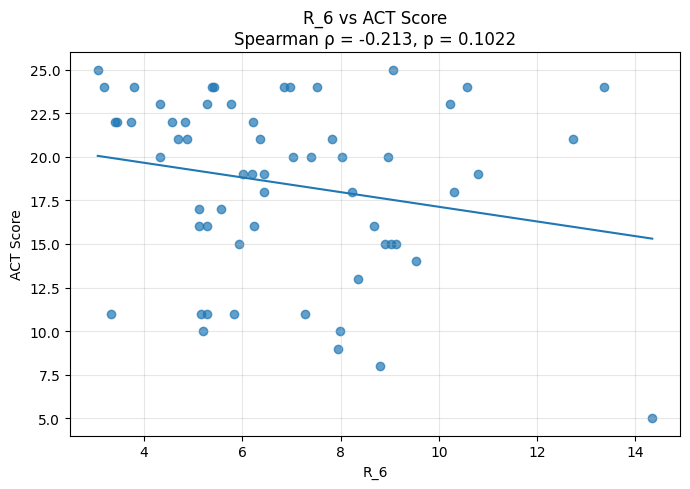

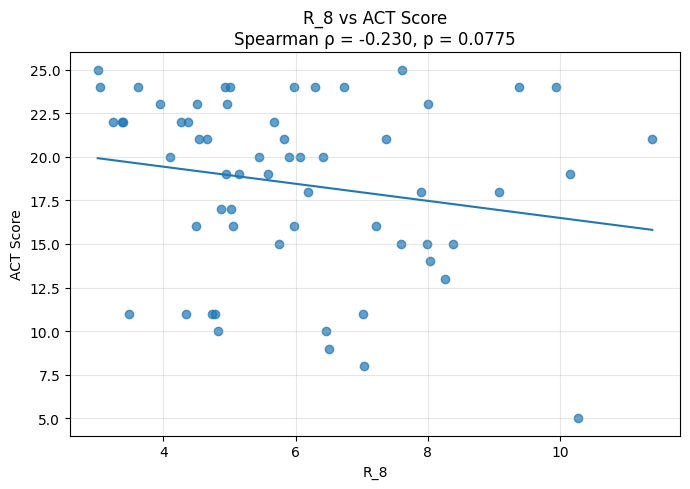

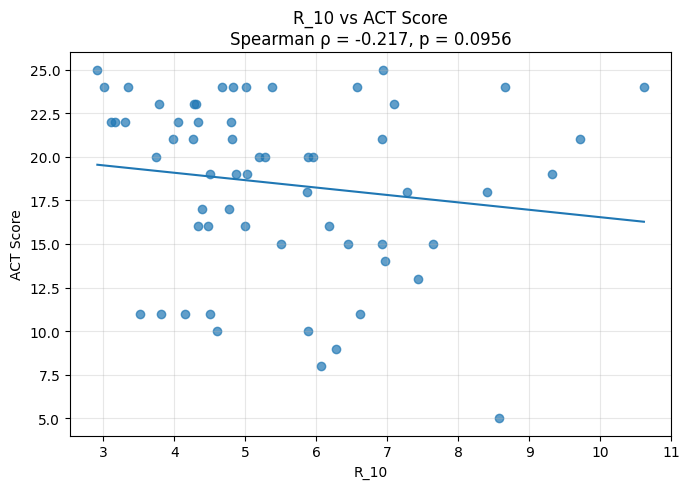

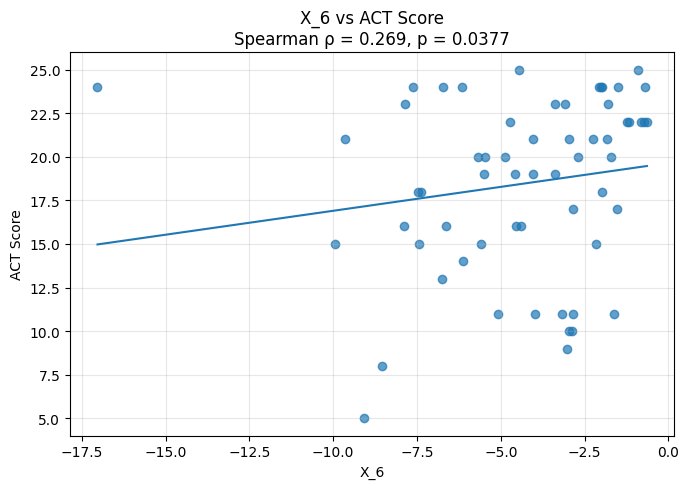

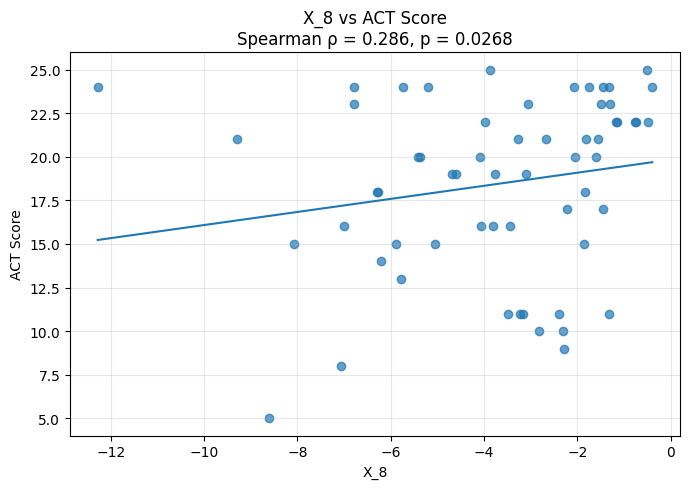

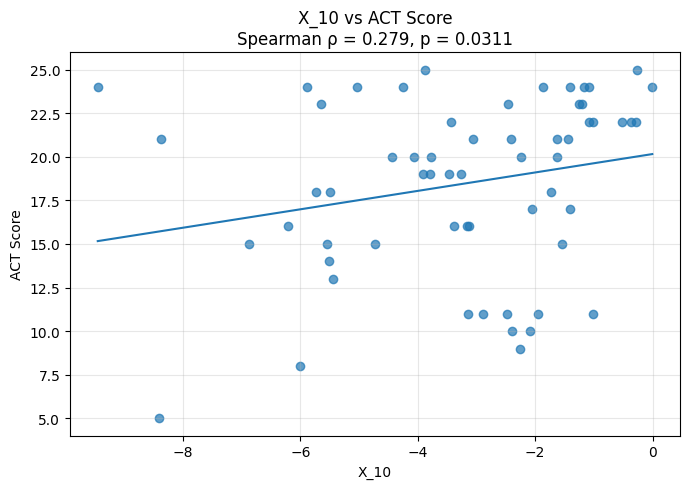

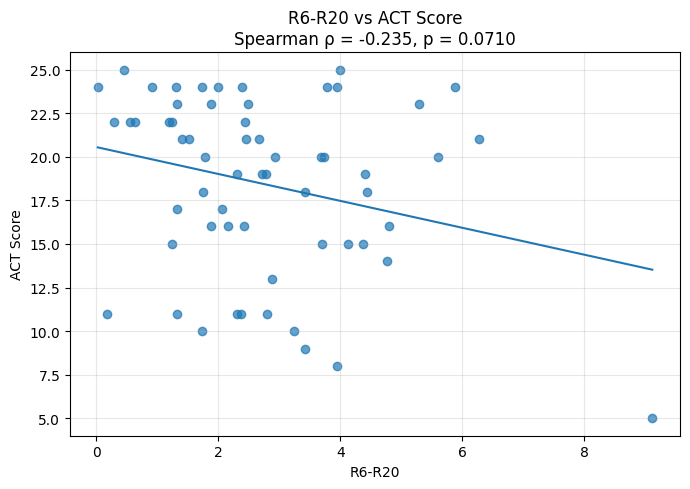

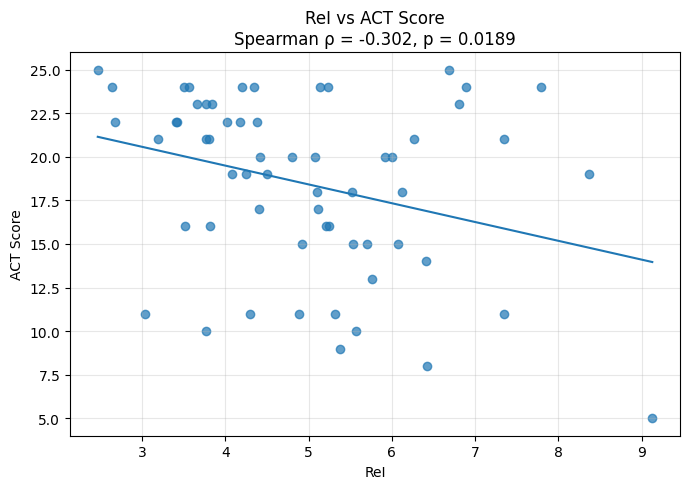

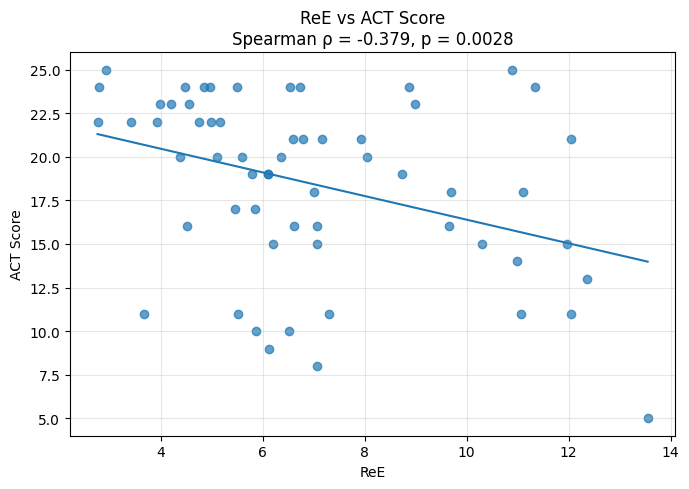

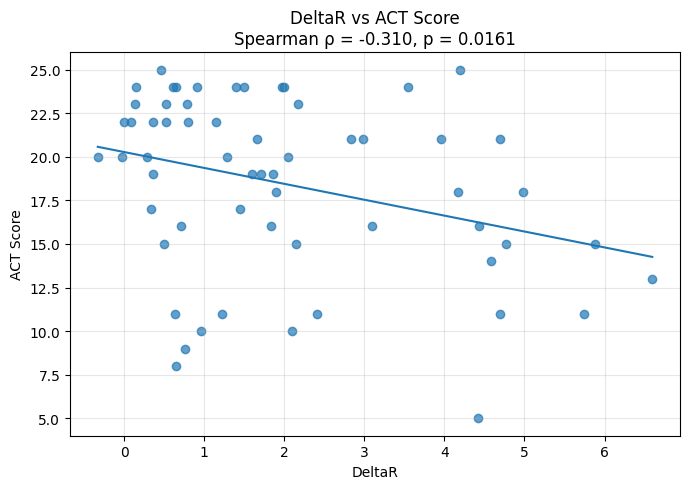

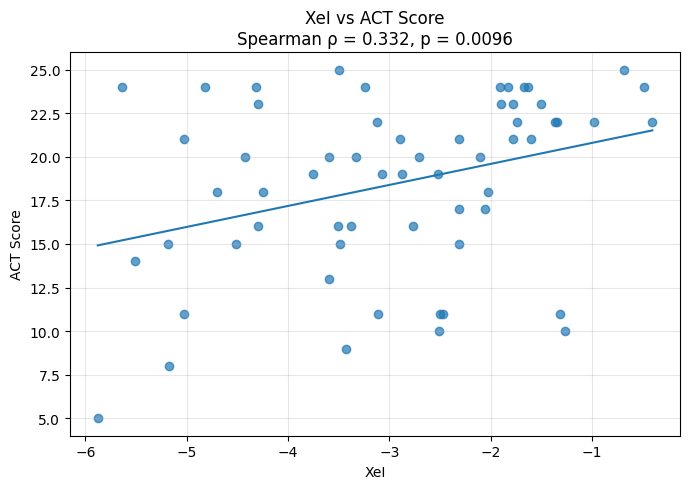

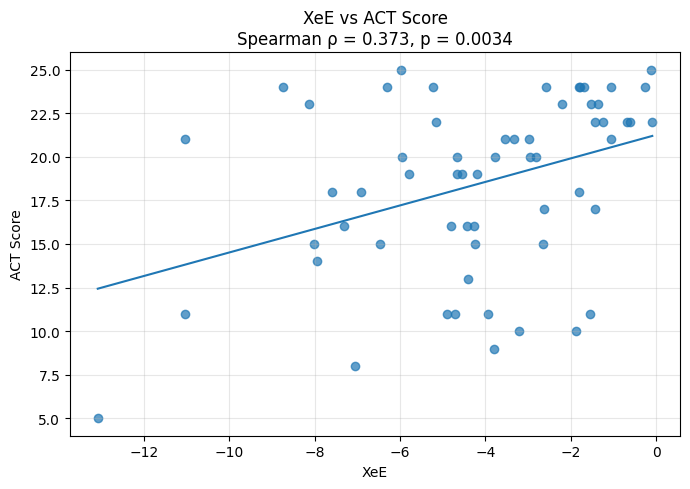

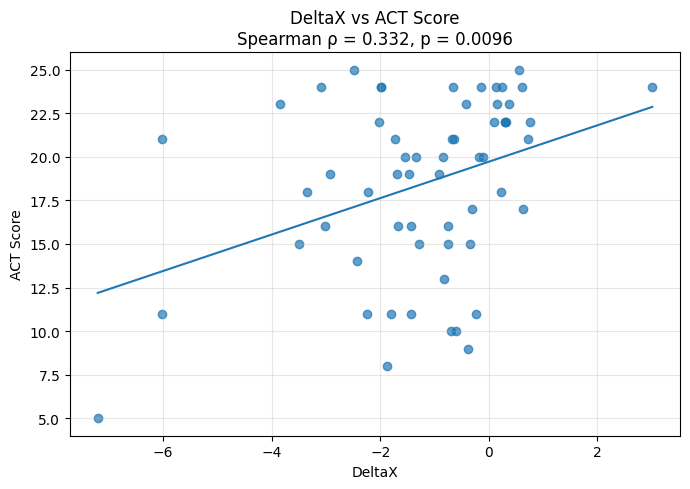

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import spearmanr

# ============================================================
# ALL FOT FEATURES
# ============================================================

fot_features = [
    "R_6",
    "R_8",
    "R_10",
    "X_6",
    "X_8",
    "X_10",
    "R6-R20",
    "ReI",
    "ReE",
    "DeltaR",
    "XeI",
    "XeE",
    "DeltaX"
]

# ============================================================
# CREATE SCATTER PLOT FOR EVERY FOT FEATURE
# ============================================================

for feature in fot_features:

    data = df[[feature, "ACT_score"]].dropna()

    rho, p_value = spearmanr(
        data[feature],
        data["ACT_score"]
    )

    # Linear trend line - only for visual guidance
    x = data[feature].to_numpy(dtype=float)
    y = data["ACT_score"].to_numpy(dtype=float)

    slope, intercept = np.polyfit(x, y, 1)

    x_line = np.linspace(
        x.min(),
        x.max(),
        100
    )

    y_line = slope * x_line + intercept

    # --------------------------------------------------------
    # PLOT
    # --------------------------------------------------------

    plt.figure(figsize=(7, 5))

    plt.scatter(
        x,
        y,
        alpha=0.7
    )

    plt.plot(
        x_line,
        y_line
    )

    plt.xlabel(feature)
    plt.ylabel("ACT Score")

    plt.title(
        f"{feature} vs ACT Score\n"
        f"Spearman ρ = {rho:.3f}, p = {p_value:.4f}"
    )

    plt.grid(
        alpha=0.3
    )

    plt.tight_layout()

    plt.show()

    plt.close()

FOT FEATURE ↔ FOT FEATURE SPEARMAN CORRELATION MATRIX
          R_6    R_8   R_10    X_6    X_8   X_10  R6-R20    ReI    ReE  \
R_6     1.000  0.968  0.955 -0.822 -0.845 -0.873   0.932  0.807  0.735   
R_8     0.968  1.000  0.980 -0.770 -0.798 -0.831   0.859  0.813  0.801   
R_10    0.955  0.980  1.000 -0.727 -0.761 -0.795   0.816  0.810  0.784   
X_6    -0.822 -0.770 -0.727  1.000  0.981  0.970  -0.878 -0.568 -0.605   
X_8    -0.845 -0.798 -0.761  0.981  1.000  0.991  -0.897 -0.609 -0.641   
X_10   -0.873 -0.831 -0.795  0.970  0.991  1.000  -0.919 -0.635 -0.658   
R6-R20  0.932  0.859  0.816 -0.878 -0.897 -0.919   1.000  0.696  0.627   
ReI     0.807  0.813  0.810 -0.568 -0.609 -0.635   0.696  1.000  0.806   
ReE     0.735  0.801  0.784 -0.605 -0.641 -0.658   0.627  0.806  1.000   
DeltaR  0.491  0.570  0.562 -0.500 -0.519 -0.513   0.409  0.437  0.853   
XeI    -0.849 -0.818 -0.789  0.881  0.899  0.907  -0.855 -0.760 -0.724   
XeE    -0.723 -0.689 -0.658  0.836  0.860  0.853  -0.761 -

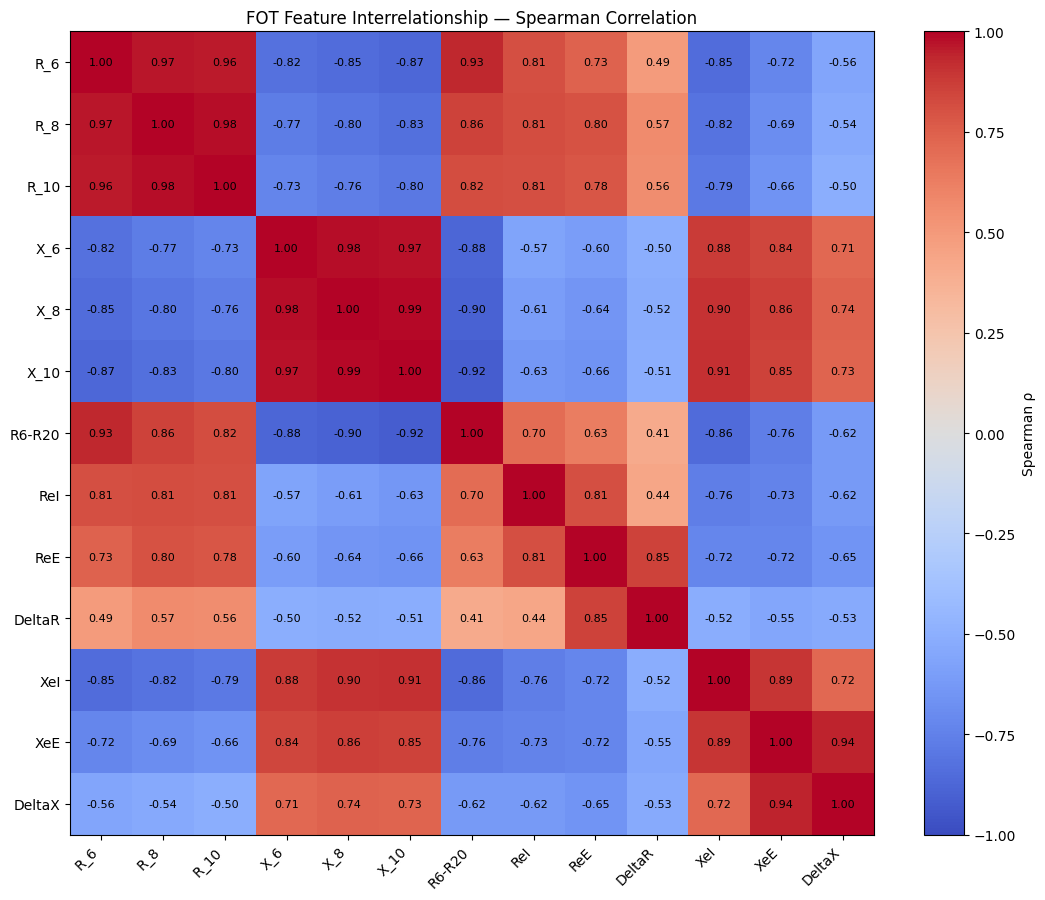


Files saved:
fot_feature_correlation_matrix.csv
fot_feature_correlation_pairs.csv
fot_feature_correlation_heatmap.png


In [ ]:
# ============================================================
# COMPLETE FOT ↔ FOT SPEARMAN CORRELATION MATRIX
# ============================================================

import pandas as pd
import matplotlib.pyplot as plt

# ------------------------------------------------------------
# ALL 13 FOT FEATURES
# ------------------------------------------------------------

fot_features = [
    "R_6",
    "R_8",
    "R_10",
    "X_6",
    "X_8",
    "X_10",
    "R6-R20",
    "ReI",
    "ReE",
    "DeltaR",
    "XeI",
    "XeE",
    "DeltaX"
]

# ------------------------------------------------------------
# CALCULATE SPEARMAN CORRELATION DIRECTLY
# ------------------------------------------------------------

corr_matrix = df[fot_features].corr(
    method="spearman"
)

# ------------------------------------------------------------
# PRINT MATRIX
# ------------------------------------------------------------

print("=" * 100)
print("FOT FEATURE ↔ FOT FEATURE SPEARMAN CORRELATION MATRIX")
print("=" * 100)

print(corr_matrix.round(3))

# ------------------------------------------------------------
# FIND FEATURE PAIRS
# ------------------------------------------------------------

pairs = []

for i in range(len(fot_features)):

    for j in range(i + 1, len(fot_features)):

        feature_1 = fot_features[i]
        feature_2 = fot_features[j]

        rho = corr_matrix.loc[
            feature_1,
            feature_2
        ]

        pairs.append({
            "Feature_1": feature_1,
            "Feature_2": feature_2,
            "Spearman_Rho": rho,
            "Absolute_Rho": abs(rho)
        })

pairs_df = pd.DataFrame(pairs)

# ------------------------------------------------------------
# SORT BY ABSOLUTE CORRELATION
# ------------------------------------------------------------

pairs_df = pairs_df.sort_values(
    "Absolute_Rho",
    ascending=False
).reset_index(drop=True)

print("\n" + "=" * 100)
print("FEATURE PAIRS — STRONGEST CORRELATION FIRST")
print("=" * 100)

print(
    pairs_df.round(3).to_string(index=False)
)

# ------------------------------------------------------------
# HIGH CORRELATION
# ------------------------------------------------------------

print("\n" + "=" * 100)
print("HIGHLY CORRELATED PAIRS | |rho| >= 0.70")
print("=" * 100)

high_corr = pairs_df[
    pairs_df["Absolute_Rho"] >= 0.70
]

if len(high_corr) > 0:
    print(
        high_corr.round(3).to_string(index=False)
    )
else:
    print("No pairs with |rho| >= 0.70")

# ------------------------------------------------------------
# SAVE RESULTS
# ------------------------------------------------------------

corr_matrix.to_csv(
    "fot_feature_correlation_matrix.csv"
)

pairs_df.to_csv(
    "fot_feature_correlation_pairs.csv",
    index=False
)

# ------------------------------------------------------------
# HEATMAP
# ------------------------------------------------------------

plt.figure(figsize=(11, 9))

plt.imshow(
    corr_matrix,
    vmin=-1,
    vmax=1,
    cmap="coolwarm"
)

plt.colorbar(
    label="Spearman ρ"
)

plt.xticks(
    range(len(fot_features)),
    fot_features,
    rotation=45,
    ha="right"
)

plt.yticks(
    range(len(fot_features)),
    fot_features
)

# Add values inside cells
for i in range(len(fot_features)):
    for j in range(len(fot_features)):

        value = corr_matrix.iloc[i, j]

        plt.text(
            j,
            i,
            f"{value:.2f}",
            ha="center",
            va="center",
            fontsize=8
        )

plt.title(
    "FOT Feature Interrelationship — Spearman Correlation"
)

plt.tight_layout()

plt.savefig(
    "fot_feature_correlation_heatmap.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("\nFiles saved:")
print("fot_feature_correlation_matrix.csv")
print("fot_feature_correlation_pairs.csv")
print("fot_feature_correlation_heatmap.png")

FOT ↔ ACT SPEARMAN CORRELATION
Feature  Spearman_Rho  p_value  Absolute_Rho
    XeE        0.3727   0.0034        0.3727
 DeltaX        0.3320   0.0096        0.3320
    XeI        0.3319   0.0096        0.3319
    X_8        0.2860   0.0268        0.2860
   X_10        0.2786   0.0311        0.2786
    X_6        0.2690   0.0377        0.2690
    R_6       -0.2130   0.1022        0.2130
   R_10       -0.2172   0.0956        0.2172
    R_8       -0.2297   0.0775        0.2297
 R6-R20       -0.2347   0.0710        0.2347
    ReI       -0.3022   0.0189        0.3022
 DeltaR       -0.3096   0.0161        0.3096
    ReE       -0.3792   0.0028        0.3792


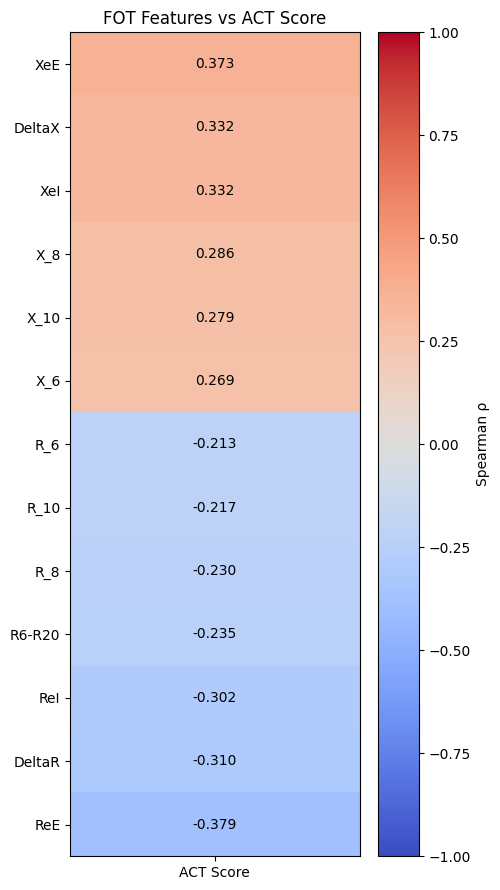


Saved:
fot_act_correlation_summary.csv
fot_act_correlation_heatmap.png


In [ ]:
# ============================================================
# FOT ↔ ACT SCORE CORRELATION HEATMAP
# ============================================================

import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import spearmanr

# ------------------------------------------------------------
# ALL FOT FEATURES
# ------------------------------------------------------------

fot_features = [
    "R_6",
    "R_8",
    "R_10",
    "X_6",
    "X_8",
    "X_10",
    "R6-R20",
    "ReI",
    "ReE",
    "DeltaR",
    "XeI",
    "XeE",
    "DeltaX"
]

# ------------------------------------------------------------
# CALCULATE CORRELATION WITH ACT
# ------------------------------------------------------------

results = []

for feature in fot_features:

    pair = df[[feature, "ACT_score"]].dropna()

    rho, p_value = spearmanr(
        pair[feature],
        pair["ACT_score"]
    )

    results.append({
        "Feature": feature,
        "Spearman_Rho": rho,
        "p_value": p_value
    })

results_df = pd.DataFrame(results)

# ------------------------------------------------------------
# SORT BY CORRELATION
# ------------------------------------------------------------

results_df["Absolute_Rho"] = (
    results_df["Spearman_Rho"].abs()
)

results_df = results_df.sort_values(
    "Spearman_Rho",
    ascending=False
).reset_index(drop=True)

# ------------------------------------------------------------
# PRINT RESULTS
# ------------------------------------------------------------

print("=" * 80)
print("FOT ↔ ACT SPEARMAN CORRELATION")
print("=" * 80)

print(
    results_df.round(4).to_string(index=False)
)

# ------------------------------------------------------------
# CREATE 13 × 1 MATRIX
# ------------------------------------------------------------

heatmap_data = results_df.set_index(
    "Feature"
)[["Spearman_Rho"]]

# ------------------------------------------------------------
# HEATMAP
# ------------------------------------------------------------

plt.figure(figsize=(5, 9))

plt.imshow(
    heatmap_data.values,
    cmap="coolwarm",
    vmin=-1,
    vmax=1,
    aspect="auto"
)

plt.colorbar(
    label="Spearman ρ"
)

plt.xticks(
    [0],
    ["ACT Score"]
)

plt.yticks(
    range(len(heatmap_data.index)),
    heatmap_data.index
)

# Add correlation values
for i, value in enumerate(
    heatmap_data["Spearman_Rho"]
):

    plt.text(
        0,
        i,
        f"{value:.3f}",
        ha="center",
        va="center"
    )

plt.title(
    "FOT Features vs ACT Score"
)

plt.tight_layout()

plt.savefig(
    "fot_act_correlation_heatmap.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

# ------------------------------------------------------------
# SAVE TABLE
# ------------------------------------------------------------

results_df.to_csv(
    "fot_act_correlation_summary.csv",
    index=False
)

print("\nSaved:")
print("fot_act_correlation_summary.csv")
print("fot_act_correlation_heatmap.png")

In [ ]:
# ============================================================
# BUILD CANDIDATE FOT FEATURE SETS
# ============================================================

# All available FOT features in our dataset
all_fot_features = [
    "R_6",
    "R_8",
    "R_10",
    "X_6",
    "X_8",
    "X_10",
    "R6-R20",
    "ReI",
    "ReE",
    "DeltaR",
    "XeI",
    "XeE",
    "DeltaX"
]

# ------------------------------------------------------------
# SET A — ALL FOT FEATURES
# ------------------------------------------------------------

set_A_all = [
    "R_6",
    "R_8",
    "R_10",
    "X_6",
    "X_8",
    "X_10",
    "R6-R20",
    "ReI",
    "ReE",
    "DeltaR",
    "XeI",
    "XeE",
    "DeltaX"
]

# ------------------------------------------------------------
# SET B — FREQUENCY-DOMAIN FEATURES
# ------------------------------------------------------------

set_B_frequency = [
    "R_6",
    "R_8",
    "R_10",
    "X_6",
    "X_8",
    "X_10",
    "R6-R20"
]

# ------------------------------------------------------------
# SET C — INSPIRATORY / EXPIRATORY FEATURES
# ------------------------------------------------------------

set_C_insp_exp = [
    "ReI",
    "ReE",
    "XeI",
    "XeE"
]

# ------------------------------------------------------------
# SET D — DELTA FEATURES
# ------------------------------------------------------------

set_D_delta = [
    "DeltaR",
    "DeltaX"
]

# ------------------------------------------------------------
# SET E — COMPACT REPRESENTATIVE FEATURES
# ------------------------------------------------------------
# This is intentionally NOT chosen using ACT correlations.
# It is only a small structural candidate set for comparison.

set_E_compact = [
    "R_6",
    "X_6",
    "DeltaR",
    "DeltaX"
]

# ------------------------------------------------------------
# STORE ALL SETS IN ONE DICTIONARY
# ------------------------------------------------------------

feature_sets = {
    "Set_A_All": set_A_all,
    "Set_B_Frequency": set_B_frequency,
    "Set_C_Insp_Exp": set_C_insp_exp,
    "Set_D_Delta": set_D_delta,
    "Set_E_Compact": set_E_compact
}

# ============================================================
# VERIFY EVERY FEATURE EXISTS
# ============================================================

print("=" * 70)
print("CANDIDATE FEATURE SETS")
print("=" * 70)

for name, features in feature_sets.items():

    missing = [
        feature
        for feature in features
        if feature not in df.columns
    ]

    print(f"\n{name}")
    print("-" * 40)
    print("Number of features:", len(features))
    print("Features:", features)

    if missing:
        print("MISSING:", missing)
    else:
        print("Status: OK")

# ============================================================
# CHECK THAT ACT VARIABLES ARE NOT IN ANY SET
# ============================================================

forbidden = {
    "ACT_score",
    "ACT_control",
    "ACT_control_label"
}

for name, features in feature_sets.items():

    leakage_features = [
        feature
        for feature in features
        if feature in forbidden
    ]

    if leakage_features:
        raise ValueError(
            f"Potential target leakage in {name}: {leakage_features}"
        )

print("\n" + "=" * 70)
print("LEAKAGE CHECK")
print("=" * 70)
print("No ACT target variables are present in any feature set.")

CANDIDATE FEATURE SETS

Set_A_All
----------------------------------------
Number of features: 13
Features: ['R_6', 'R_8', 'R_10', 'X_6', 'X_8', 'X_10', 'R6-R20', 'ReI', 'ReE', 'DeltaR', 'XeI', 'XeE', 'DeltaX']
Status: OK

Set_B_Frequency
----------------------------------------
Number of features: 7
Features: ['R_6', 'R_8', 'R_10', 'X_6', 'X_8', 'X_10', 'R6-R20']
Status: OK

Set_C_Insp_Exp
----------------------------------------
Number of features: 4
Features: ['ReI', 'ReE', 'XeI', 'XeE']
Status: OK

Set_D_Delta
----------------------------------------
Number of features: 2
Features: ['DeltaR', 'DeltaX']
Status: OK

Set_E_Compact
----------------------------------------
Number of features: 4
Features: ['R_6', 'X_6', 'DeltaR', 'DeltaX']
Status: OK

LEAKAGE CHECK
No ACT target variables are present in any feature set.


In [ ]:
# ============================================================
# FIXED PATIENT-LEVEL TRAIN / TEST SPLIT
# ============================================================

from sklearn.model_selection import train_test_split

# Target
target = "ACT_control"

# Use the patient IDs so we can explicitly track the split
patient_ids = df["id"].copy()
y = df[target].copy()

# ------------------------------------------------------------
# 80% TRAIN / 20% TEST
# Stratified = keeps the two ACT classes balanced
# random_state = makes the split reproducible
# ------------------------------------------------------------

train_ids, test_ids = train_test_split(
    patient_ids,
    test_size=0.20,
    random_state=42,
    stratify=y
)

# ------------------------------------------------------------
# CREATE TRAIN / TEST DATA
# ------------------------------------------------------------

df_train = df[
    df["id"].isin(train_ids)
].copy()

df_test = df[
    df["id"].isin(test_ids)
].copy()

# ============================================================
# CHECK SPLIT
# ============================================================

print("=" * 70)
print("FIXED TRAIN / TEST SPLIT")
print("=" * 70)

print("Total patients :", len(df))
print("Training       :", len(df_train))
print("Test           :", len(df_test))

print("\nTraining class distribution:")
print(
    df_train[target]
    .value_counts()
    .sort_index()
)

print("\nTraining class percentage:")
print(
    (
        df_train[target]
        .value_counts(normalize=True)
        .sort_index()
        * 100
    ).round(2)
)

print("\nTest class distribution:")
print(
    df_test[target]
    .value_counts()
    .sort_index()
)

print("\nTest class percentage:")
print(
    (
        df_test[target]
        .value_counts(normalize=True)
        .sort_index()
        * 100
    ).round(2)
)

# ============================================================
# VERIFY NO PATIENT OVERLAP
# ============================================================

train_id_set = set(df_train["id"])
test_id_set = set(df_test["id"])

overlap = train_id_set.intersection(test_id_set)

print("\nPatient overlap:", len(overlap))

if len(overlap) > 0:
    raise ValueError(
        "DATA LEAKAGE: Patient appears in both train and test!"
    )

print("No patient overlap.")
print("Test set is now LOCKED.")

FIXED TRAIN / TEST SPLIT
Total patients : 60
Training       : 48
Test           : 12

Training class distribution:
ACT_control
0    23
1    25
Name: count, dtype: int64

Training class percentage:
ACT_control
0    47.92
1    52.08
Name: proportion, dtype: float64

Test class distribution:
ACT_control
0    6
1    6
Name: count, dtype: int64

Test class percentage:
ACT_control
0    50.0
1    50.0
Name: proportion, dtype: float64

Patient overlap: 0
No patient overlap.
Test set is now LOCKED.


In [ ]:
# ============================================================
# CREATE FIXED STRATIFIED CROSS-VALIDATION FOLDS
# ============================================================

from sklearn.model_selection import StratifiedKFold

# ------------------------------------------------------------
# TRAINING DATA ONLY
# ------------------------------------------------------------

X_train_full = df_train.copy()
y_train_full = df_train["ACT_control"].copy()

# ------------------------------------------------------------
# 5-FOLD STRATIFIED CROSS-VALIDATION
# ------------------------------------------------------------

skf = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

print("=" * 70)
print("5-FOLD STRATIFIED CROSS-VALIDATION")
print("=" * 70)

print("Total training patients:", len(df_train))
print("Number of folds:", skf.n_splits)

# ------------------------------------------------------------
# CREATE AND STORE FOLDS
# ------------------------------------------------------------

cv_folds = []

for fold_number, (train_idx, val_idx) in enumerate(
    skf.split(X_train_full, y_train_full),
    start=1
):

    fold_train = df_train.iloc[train_idx]
    fold_val = df_train.iloc[val_idx]

    cv_folds.append(
        (train_idx, val_idx)
    )

    print("\nFold", fold_number)
    print("-" * 40)

    print("Fold training patients:", len(train_idx))
    print("Fold validation patients:", len(val_idx))

    print(
        "Training classes:",
        fold_train["ACT_control"]
        .value_counts()
        .sort_index()
        .to_dict()
    )

    print(
        "Validation classes:",
        fold_val["ACT_control"]
        .value_counts()
        .sort_index()
        .to_dict()
    )

# ------------------------------------------------------------
# FINAL CHECK
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("CROSS-VALIDATION SETUP COMPLETE")
print("=" * 70)

print(
    "All folds are stratified and reproducible."
)

print(
    "The 12-patient final test set remains untouched."
)

5-FOLD STRATIFIED CROSS-VALIDATION
Total training patients: 48
Number of folds: 5

Fold 1
----------------------------------------
Fold training patients: 38
Fold validation patients: 10
Training classes: {0: 18, 1: 20}
Validation classes: {0: 5, 1: 5}

Fold 2
----------------------------------------
Fold training patients: 38
Fold validation patients: 10
Training classes: {0: 18, 1: 20}
Validation classes: {0: 5, 1: 5}

Fold 3
----------------------------------------
Fold training patients: 38
Fold validation patients: 10
Training classes: {0: 18, 1: 20}
Validation classes: {0: 5, 1: 5}

Fold 4
----------------------------------------
Fold training patients: 39
Fold validation patients: 9
Training classes: {0: 19, 1: 20}
Validation classes: {0: 4, 1: 5}

Fold 5
----------------------------------------
Fold training patients: 39
Fold validation patients: 9
Training classes: {0: 19, 1: 20}
Validation classes: {0: 4, 1: 5}

CROSS-VALIDATION SETUP COMPLETE
All folds are stratified and rep

In [ ]:
# ============================================================
# LEAKAGE-SAFE LOGISTIC REGRESSION
# EVALUATE ALL FEATURE SETS USING FIXED CV FOLDS
# ============================================================

import numpy as np
import pandas as pd

from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score
)

# ============================================================
# STORAGE FOR RESULTS
# ============================================================

cv_results = []

# ============================================================
# RUN EACH FEATURE SET
# ============================================================

for set_name, features in feature_sets.items():

    print("\n" + "=" * 80)
    print(set_name)
    print("=" * 80)

    fold_scores = []

    # --------------------------------------------------------
    # FIXED 5-FOLD SPLITS
    # --------------------------------------------------------

    for fold_number, (train_idx, val_idx) in enumerate(
        cv_folds,
        start=1
    ):

        # -----------------------------------------------
        # Get feature values
        # -----------------------------------------------

        X_train_fold = df_train.iloc[
            train_idx
        ][features]

        X_val_fold = df_train.iloc[
            val_idx
        ][features]

        y_train_fold = df_train.iloc[
            train_idx
        ][target]

        y_val_fold = df_train.iloc[
            val_idx
        ][target]

        # -----------------------------------------------
        # Leakage-safe pipeline
        # -----------------------------------------------

        model = Pipeline([
            (
                "scaler",
                StandardScaler()
            ),
            (
                "classifier",
                LogisticRegression(
                    max_iter=5000,
                    random_state=42
                )
            )
        ])

        # -----------------------------------------------
        # Train ONLY on fold training data
        # -----------------------------------------------

        model.fit(
            X_train_fold,
            y_train_fold
        )

        # -----------------------------------------------
        # Predict validation fold
        # -----------------------------------------------

        y_pred = model.predict(
            X_val_fold
        )

        y_prob = model.predict_proba(
            X_val_fold
        )[:, 1]

        # -----------------------------------------------
        # Metrics
        # -----------------------------------------------

        accuracy = accuracy_score(
            y_val_fold,
            y_pred
        )

        precision = precision_score(
            y_val_fold,
            y_pred,
            zero_division=0
        )

        recall = recall_score(
            y_val_fold,
            y_pred,
            zero_division=0
        )

        f1 = f1_score(
            y_val_fold,
            y_pred,
            zero_division=0
        )

        auc = roc_auc_score(
            y_val_fold,
            y_prob
        )

        fold_scores.append({
            "Feature_Set": set_name,
            "Fold": fold_number,
            "Accuracy": accuracy,
            "Precision": precision,
            "Recall": recall,
            "F1": f1,
            "ROC_AUC": auc
        })

        print(
            f"Fold {fold_number}: "
            f"Accuracy={accuracy:.3f}, "
            f"F1={f1:.3f}, "
            f"ROC-AUC={auc:.3f}"
        )

    # --------------------------------------------------------
    # STORE FOLD RESULTS
    # --------------------------------------------------------

    cv_results.extend(
        fold_scores
    )

# ============================================================
# CONVERT TO DATAFRAME
# ============================================================

cv_results_df = pd.DataFrame(
    cv_results
)

# ============================================================
# SUMMARY
# ============================================================

summary_df = (
    cv_results_df
    .groupby("Feature_Set")[
        [
            "Accuracy",
            "Precision",
            "Recall",
            "F1",
            "ROC_AUC"
        ]
    ]
    .agg(["mean", "std"])
)

print("\n" + "=" * 100)
print("LOGISTIC REGRESSION - CROSS-VALIDATION SUMMARY")
print("=" * 100)

print(
    summary_df.round(3)
)

# ============================================================
# SAVE RESULTS
# ============================================================

cv_results_df.to_csv(
    "logistic_regression_cv_fold_results.csv",
    index=False
)

summary_df.to_csv(
    "logistic_regression_cv_summary.csv"
)

print("\nSaved:")
print("logistic_regression_cv_fold_results.csv")
print("logistic_regression_cv_summary.csv")


Set_A_All
Fold 1: Accuracy=0.300, F1=0.222, ROC-AUC=0.360
Fold 2: Accuracy=0.800, F1=0.833, ROC-AUC=0.840
Fold 3: Accuracy=0.700, F1=0.727, ROC-AUC=0.800
Fold 4: Accuracy=0.444, F1=0.444, ROC-AUC=0.400
Fold 5: Accuracy=0.556, F1=0.600, ROC-AUC=0.450

Set_B_Frequency
Fold 1: Accuracy=0.400, F1=0.500, ROC-AUC=0.440
Fold 2: Accuracy=0.600, F1=0.667, ROC-AUC=0.640
Fold 3: Accuracy=0.500, F1=0.545, ROC-AUC=0.440
Fold 4: Accuracy=0.333, F1=0.250, ROC-AUC=0.200
Fold 5: Accuracy=0.556, F1=0.667, ROC-AUC=0.500

Set_C_Insp_Exp
Fold 1: Accuracy=0.300, F1=0.222, ROC-AUC=0.360
Fold 2: Accuracy=0.800, F1=0.833, ROC-AUC=0.920
Fold 3: Accuracy=0.700, F1=0.727, ROC-AUC=0.800
Fold 4: Accuracy=0.444, F1=0.444, ROC-AUC=0.650
Fold 5: Accuracy=0.556, F1=0.600, ROC-AUC=0.600

Set_D_Delta
Fold 1: Accuracy=0.300, F1=0.222, ROC-AUC=0.440
Fold 2: Accuracy=0.800, F1=0.833, ROC-AUC=0.920
Fold 3: Accuracy=0.700, F1=0.727, ROC-AUC=0.800
Fold 4: Accuracy=0.556, F1=0.600, ROC-AUC=0.750
Fold 5: Accuracy=0.556, F1=0.66

In [ ]:
# ============================================================
# LEAKAGE-SAFE SVM
# ALL FEATURE SETS
# FIXED 5-FOLD CROSS-VALIDATION
# ============================================================

import numpy as np
import pandas as pd

from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score
)

# ============================================================
# STORAGE
# ============================================================

svm_results = []

# ============================================================
# EVALUATE EACH FEATURE SET
# ============================================================

for set_name, features in feature_sets.items():

    print("\n" + "=" * 80)
    print(set_name)
    print("=" * 80)

    for fold_number, (train_idx, val_idx) in enumerate(
        cv_folds,
        start=1
    ):

        # ----------------------------------------------------
        # SELECT FOLD DATA
        # ----------------------------------------------------

        X_train_fold = df_train.iloc[
            train_idx
        ][features]

        X_val_fold = df_train.iloc[
            val_idx
        ][features]

        y_train_fold = df_train.iloc[
            train_idx
        ][target]

        y_val_fold = df_train.iloc[
            val_idx
        ][target]

        # ----------------------------------------------------
        # LEAKAGE-SAFE PIPELINE
        # ----------------------------------------------------

        model = Pipeline([
            (
                "scaler",
                StandardScaler()
            ),
            (
                "classifier",
                SVC(
                    kernel="rbf",
                    probability=True,
                    random_state=42
                )
            )
        ])

        # ----------------------------------------------------
        # TRAIN
        # ----------------------------------------------------

        model.fit(
            X_train_fold,
            y_train_fold
        )

        # ----------------------------------------------------
        # PREDICT
        # ----------------------------------------------------

        y_pred = model.predict(
            X_val_fold
        )

        y_prob = model.predict_proba(
            X_val_fold
        )[:, 1]

        # ----------------------------------------------------
        # METRICS
        # ----------------------------------------------------

        accuracy = accuracy_score(
            y_val_fold,
            y_pred
        )

        precision = precision_score(
            y_val_fold,
            y_pred,
            zero_division=0
        )

        recall = recall_score(
            y_val_fold,
            y_pred,
            zero_division=0
        )

        f1 = f1_score(
            y_val_fold,
            y_pred,
            zero_division=0
        )

        auc = roc_auc_score(
            y_val_fold,
            y_prob
        )

        svm_results.append({
            "Feature_Set": set_name,
            "Fold": fold_number,
            "Accuracy": accuracy,
            "Precision": precision,
            "Recall": recall,
            "F1": f1,
            "ROC_AUC": auc
        })

        print(
            f"Fold {fold_number}: "
            f"Accuracy={accuracy:.3f}, "
            f"F1={f1:.3f}, "
            f"ROC-AUC={auc:.3f}"
        )

# ============================================================
# RESULTS DATAFRAME
# ============================================================

svm_results_df = pd.DataFrame(
    svm_results
)

# ============================================================
# SUMMARY
# ============================================================

svm_summary_df = (
    svm_results_df
    .groupby("Feature_Set")[
        [
            "Accuracy",
            "Precision",
            "Recall",
            "F1",
            "ROC_AUC"
        ]
    ]
    .agg(["mean", "std"])
)

print("\n" + "=" * 100)
print("SVM - CROSS-VALIDATION SUMMARY")
print("=" * 100)

print(
    svm_summary_df.round(3)
)

# ============================================================
# SAVE
# ============================================================

svm_results_df.to_csv(
    "svm_cv_fold_results.csv",
    index=False
)

svm_summary_df.to_csv(
    "svm_cv_summary.csv"
)

print("\nSaved:")
print("svm_cv_fold_results.csv")
print("svm_cv_summary.csv")


Set_A_All
Fold 1: Accuracy=0.600, F1=0.500, ROC-AUC=0.440
Fold 2: Accuracy=0.700, F1=0.727, ROC-AUC=0.360
Fold 3: Accuracy=0.600, F1=0.500, ROC-AUC=0.700
Fold 4: Accuracy=0.444, F1=0.286, ROC-AUC=0.500
Fold 5: Accuracy=0.556, F1=0.600, ROC-AUC=0.700

Set_B_Frequency
Fold 1: Accuracy=0.600, F1=0.500, ROC-AUC=0.480
Fold 2: Accuracy=0.600, F1=0.667, ROC-AUC=0.360
Fold 3: Accuracy=0.500, F1=0.444, ROC-AUC=0.640
Fold 4: Accuracy=0.444, F1=0.286, ROC-AUC=0.500
Fold 5: Accuracy=0.667, F1=0.727, ROC-AUC=0.300

Set_C_Insp_Exp
Fold 1: Accuracy=0.500, F1=0.444, ROC-AUC=0.560
Fold 2: Accuracy=0.700, F1=0.727, ROC-AUC=0.320
Fold 3: Accuracy=0.600, F1=0.500, ROC-AUC=0.640
Fold 4: Accuracy=0.556, F1=0.333, ROC-AUC=0.550
Fold 5: Accuracy=0.556, F1=0.600, ROC-AUC=0.750

Set_D_Delta
Fold 1: Accuracy=0.300, F1=0.364, ROC-AUC=0.400
Fold 2: Accuracy=0.800, F1=0.833, ROC-AUC=0.120
Fold 3: Accuracy=0.800, F1=0.750, ROC-AUC=0.120
Fold 4: Accuracy=0.444, F1=0.286, ROC-AUC=0.550
Fold 5: Accuracy=0.556, F1=0.60

In [ ]:
# ============================================================
# LEAKAGE-SAFE RANDOM FOREST
# ALL FEATURE SETS
# SAME FIXED 5-FOLD CV
# ============================================================

import numpy as np
import pandas as pd

from sklearn.ensemble import RandomForestClassifier

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score
)

# ============================================================
# STORAGE
# ============================================================

rf_results = []

# ============================================================
# EVALUATE EACH FEATURE SET
# ============================================================

for set_name, features in feature_sets.items():

    print("\n" + "=" * 80)
    print(set_name)
    print("=" * 80)

    for fold_number, (train_idx, val_idx) in enumerate(
        cv_folds,
        start=1
    ):

        # ----------------------------------------------------
        # SELECT FOLD DATA
        # ----------------------------------------------------

        X_train_fold = df_train.iloc[
            train_idx
        ][features]

        X_val_fold = df_train.iloc[
            val_idx
        ][features]

        y_train_fold = df_train.iloc[
            train_idx
        ][target]

        y_val_fold = df_train.iloc[
            val_idx
        ][target]

        # ----------------------------------------------------
        # RANDOM FOREST
        # ----------------------------------------------------

        model = RandomForestClassifier(
            n_estimators=300,
            random_state=42,
            class_weight="balanced",
            max_features="sqrt",
            n_jobs=-1
        )

        # ----------------------------------------------------
        # TRAIN
        # ----------------------------------------------------

        model.fit(
            X_train_fold,
            y_train_fold
        )

        # ----------------------------------------------------
        # PREDICT
        # ----------------------------------------------------

        y_pred = model.predict(
            X_val_fold
        )

        y_prob = model.predict_proba(
            X_val_fold
        )[:, 1]

        # ----------------------------------------------------
        # METRICS
        # ----------------------------------------------------

        accuracy = accuracy_score(
            y_val_fold,
            y_pred
        )

        precision = precision_score(
            y_val_fold,
            y_pred,
            zero_division=0
        )

        recall = recall_score(
            y_val_fold,
            y_pred,
            zero_division=0
        )

        f1 = f1_score(
            y_val_fold,
            y_pred,
            zero_division=0
        )

        auc = roc_auc_score(
            y_val_fold,
            y_prob
        )

        rf_results.append({
            "Feature_Set": set_name,
            "Fold": fold_number,
            "Accuracy": accuracy,
            "Precision": precision,
            "Recall": recall,
            "F1": f1,
            "ROC_AUC": auc
        })

        print(
            f"Fold {fold_number}: "
            f"Accuracy={accuracy:.3f}, "
            f"F1={f1:.3f}, "
            f"ROC-AUC={auc:.3f}"
        )

# ============================================================
# RESULTS DATAFRAME
# ============================================================

rf_results_df = pd.DataFrame(
    rf_results
)

# ============================================================
# SUMMARY
# ============================================================

rf_summary_df = (
    rf_results_df
    .groupby("Feature_Set")[
        [
            "Accuracy",
            "Precision",
            "Recall",
            "F1",
            "ROC_AUC"
        ]
    ]
    .agg(["mean", "std"])
)

print("\n" + "=" * 100)
print("RANDOM FOREST - CROSS-VALIDATION SUMMARY")
print("=" * 100)

print(
    rf_summary_df.round(3)
)

# ============================================================
# SAVE
# ============================================================

rf_results_df.to_csv(
    "random_forest_cv_fold_results.csv",
    index=False
)

rf_summary_df.to_csv(
    "random_forest_cv_summary.csv"
)

print("\nSaved:")
print("random_forest_cv_fold_results.csv")
print("random_forest_cv_summary.csv")


Set_A_All
Fold 1: Accuracy=0.600, F1=0.500, ROC-AUC=0.400
Fold 2: Accuracy=0.600, F1=0.667, ROC-AUC=0.720
Fold 3: Accuracy=0.700, F1=0.667, ROC-AUC=0.840
Fold 4: Accuracy=0.667, F1=0.571, ROC-AUC=0.800
Fold 5: Accuracy=0.667, F1=0.727, ROC-AUC=0.850

Set_B_Frequency
Fold 1: Accuracy=0.400, F1=0.250, ROC-AUC=0.400
Fold 2: Accuracy=0.600, F1=0.667, ROC-AUC=0.680
Fold 3: Accuracy=0.500, F1=0.545, ROC-AUC=0.680
Fold 4: Accuracy=0.444, F1=0.286, ROC-AUC=0.600
Fold 5: Accuracy=0.889, F1=0.909, ROC-AUC=0.950

Set_C_Insp_Exp
Fold 1: Accuracy=0.700, F1=0.571, ROC-AUC=0.840
Fold 2: Accuracy=0.600, F1=0.667, ROC-AUC=0.800
Fold 3: Accuracy=0.500, F1=0.444, ROC-AUC=0.560
Fold 4: Accuracy=0.667, F1=0.571, ROC-AUC=0.550
Fold 5: Accuracy=0.667, F1=0.727, ROC-AUC=0.850

Set_D_Delta
Fold 1: Accuracy=0.600, F1=0.500, ROC-AUC=0.680
Fold 2: Accuracy=0.700, F1=0.769, ROC-AUC=0.780
Fold 3: Accuracy=0.900, F1=0.889, ROC-AUC=1.000
Fold 4: Accuracy=1.000, F1=1.000, ROC-AUC=1.000
Fold 5: Accuracy=0.778, F1=0.80

In [ ]:
# ============================================================
# XGBOOST INSTALLATION
# ============================================================

!pip install -q xgboost

In [ ]:
# ============================================================
# LEAKAGE-SAFE XGBOOST
# ALL FEATURE SETS
# SAME FIXED 5-FOLD CV
# ============================================================

import pandas as pd

from xgboost import XGBClassifier

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score
)

# ============================================================
# STORAGE
# ============================================================

xgb_results = []

# ============================================================
# EVALUATE EACH FEATURE SET
# ============================================================

for set_name, features in feature_sets.items():

    print("\n" + "=" * 80)
    print(set_name)
    print("=" * 80)

    for fold_number, (train_idx, val_idx) in enumerate(
        cv_folds,
        start=1
    ):

        # ----------------------------------------------------
        # SELECT FOLD DATA
        # ----------------------------------------------------

        X_train_fold = df_train.iloc[
            train_idx
        ][features]

        X_val_fold = df_train.iloc[
            val_idx
        ][features]

        y_train_fold = df_train.iloc[
            train_idx
        ][target]

        y_val_fold = df_train.iloc[
            val_idx
        ][target]

        # ----------------------------------------------------
        # XGBOOST
        # ----------------------------------------------------

        model = XGBClassifier(
            n_estimators=200,
            max_depth=2,
            learning_rate=0.05,
            subsample=0.8,
            colsample_bytree=0.8,
            objective="binary:logistic",
            eval_metric="logloss",
            random_state=42,
            n_jobs=-1
        )

        # ----------------------------------------------------
        # TRAIN ONLY ON TRAINING FOLD
        # ----------------------------------------------------

        model.fit(
            X_train_fold,
            y_train_fold
        )

        # ----------------------------------------------------
        # PREDICT VALIDATION FOLD
        # ----------------------------------------------------

        y_pred = model.predict(
            X_val_fold
        )

        y_prob = model.predict_proba(
            X_val_fold
        )[:, 1]

        # ----------------------------------------------------
        # METRICS
        # ----------------------------------------------------

        accuracy = accuracy_score(
            y_val_fold,
            y_pred
        )

        precision = precision_score(
            y_val_fold,
            y_pred,
            zero_division=0
        )

        recall = recall_score(
            y_val_fold,
            y_pred,
            zero_division=0
        )

        f1 = f1_score(
            y_val_fold,
            y_pred,
            zero_division=0
        )

        auc = roc_auc_score(
            y_val_fold,
            y_prob
        )

        xgb_results.append({
            "Feature_Set": set_name,
            "Fold": fold_number,
            "Accuracy": accuracy,
            "Precision": precision,
            "Recall": recall,
            "F1": f1,
            "ROC_AUC": auc
        })

        print(
            f"Fold {fold_number}: "
            f"Accuracy={accuracy:.3f}, "
            f"F1={f1:.3f}, "
            f"ROC-AUC={auc:.3f}"
        )

# ============================================================
# RESULTS DATAFRAME
# ============================================================

xgb_results_df = pd.DataFrame(
    xgb_results
)

# ============================================================
# SUMMARY
# ============================================================

xgb_summary_df = (
    xgb_results_df
    .groupby("Feature_Set")[
        [
            "Accuracy",
            "Precision",
            "Recall",
            "F1",
            "ROC_AUC"
        ]
    ]
    .agg(["mean", "std"])
)

print("\n" + "=" * 100)
print("XGBOOST - CROSS-VALIDATION SUMMARY")
print("=" * 100)

print(
    xgb_summary_df.round(3)
)

# ============================================================
# SAVE
# ============================================================

xgb_results_df.to_csv(
    "xgboost_cv_fold_results.csv",
    index=False
)

xgb_summary_df.to_csv(
    "xgboost_cv_summary.csv"
)

print("\nSaved:")
print("xgboost_cv_fold_results.csv")
print("xgboost_cv_summary.csv")


Set_A_All
Fold 1: Accuracy=0.500, F1=0.000, ROC-AUC=0.480
Fold 2: Accuracy=0.700, F1=0.727, ROC-AUC=0.740
Fold 3: Accuracy=0.600, F1=0.500, ROC-AUC=0.640
Fold 4: Accuracy=0.667, F1=0.667, ROC-AUC=0.700
Fold 5: Accuracy=0.556, F1=0.600, ROC-AUC=0.650

Set_B_Frequency
Fold 1: Accuracy=0.300, F1=0.000, ROC-AUC=0.440
Fold 2: Accuracy=0.600, F1=0.667, ROC-AUC=0.620
Fold 3: Accuracy=0.800, F1=0.800, ROC-AUC=0.840
Fold 4: Accuracy=0.667, F1=0.571, ROC-AUC=0.475
Fold 5: Accuracy=0.778, F1=0.800, ROC-AUC=0.700

Set_C_Insp_Exp
Fold 1: Accuracy=0.600, F1=0.333, ROC-AUC=0.760
Fold 2: Accuracy=0.600, F1=0.667, ROC-AUC=0.720
Fold 3: Accuracy=0.500, F1=0.444, ROC-AUC=0.440
Fold 4: Accuracy=0.667, F1=0.571, ROC-AUC=0.725
Fold 5: Accuracy=0.444, F1=0.545, ROC-AUC=0.650

Set_D_Delta
Fold 1: Accuracy=0.600, F1=0.500, ROC-AUC=0.760
Fold 2: Accuracy=0.700, F1=0.769, ROC-AUC=0.760
Fold 3: Accuracy=0.700, F1=0.571, ROC-AUC=0.840
Fold 4: Accuracy=0.889, F1=0.889, ROC-AUC=1.000
Fold 5: Accuracy=0.667, F1=0.72

In [ ]:
from sklearn.model_selection import RepeatedStratifiedKFold
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier
from sklearn.metrics import accuracy_score, f1_score, roc_auc_score
import numpy as np
import pandas as pd

# Training data only
X_train = df.loc[train_idx, fot_features]
y_train = df.loc[train_idx, "ACT_control"]

# Repeated 5-fold CV
cv = RepeatedStratifiedKFold(
    n_splits=5,
    n_repeats=10,
    random_state=42
)

models = {
    "Logistic Regression": Pipeline([
        ("scaler", StandardScaler()),
        ("model", LogisticRegression(max_iter=1000, random_state=42))
    ]),

    "SVM": Pipeline([
        ("scaler", StandardScaler()),
        ("model", SVC(kernel="rbf", probability=True, random_state=42))
    ]),

    "Random Forest": RandomForestClassifier(
        n_estimators=300,
        class_weight="balanced",
        max_features="sqrt",
        random_state=42,
        n_jobs=-1
    ),

    "XGBoost": XGBClassifier(
        n_estimators=200,
        max_depth=2,
        learning_rate=0.05,
        subsample=0.8,
        colsample_bytree=0.8,
        objective="binary:logistic",
        eval_metric="logloss",
        random_state=42,
        n_jobs=-1
    )
}

results = []

for set_name, features in feature_sets.items():

    X = X_train[features]

    for model_name, model in models.items():

        acc_scores = []
        f1_scores = []
        auc_scores = []

        for train_fold, val_fold in cv.split(X, y_train):

            X_tr = X.iloc[train_fold]
            X_val = X.iloc[val_fold]

            y_tr = y_train.iloc[train_fold]
            y_val = y_train.iloc[val_fold]

            model.fit(X_tr, y_tr)

            y_pred = model.predict(X_val)
            y_prob = model.predict_proba(X_val)[:, 1]

            acc_scores.append(accuracy_score(y_val, y_pred))
            f1_scores.append(f1_score(y_val, y_pred))
            auc_scores.append(roc_auc_score(y_val, y_prob))

        results.append({
            "Feature_Set": set_name,
            "Model": model_name,

            "Accuracy_Mean": np.mean(acc_scores),
            "Accuracy_SD": np.std(acc_scores),

            "F1_Mean": np.mean(f1_scores),
            "F1_SD": np.std(f1_scores),

            "ROC_AUC_Mean": np.mean(auc_scores),
            "ROC_AUC_SD": np.std(auc_scores)
        })

repeated_cv_results = pd.DataFrame(results)

repeated_cv_results = repeated_cv_results.sort_values(
    by="ROC_AUC_Mean",
    ascending=False
)

repeated_cv_results.round(3)

,Feature_Set,Model,Accuracy_Mean,Accuracy_SD,F1_Mean,F1_SD,ROC_AUC_Mean,ROC_AUC_SD
2,Set_A_All,Random Forest,0.673,0.156,0.679,0.173,0.810,0.170
10,Set_C_Insp_Exp,Random Forest,0.677,0.145,0.686,0.152,0.793,0.135
1,Set_A_All,SVM,0.665,0.158,0.666,0.195,0.786,0.161
18,Set_E_Compact,Random Forest,0.690,0.155,0.715,0.143,0.782,0.181
9,Set_C_Insp_Exp,SVM,0.665,0.135,0.662,0.153,0.779,0.160
11,Set_C_Insp_Exp,XGBoost,0.639,0.141,0.661,0.155,0.768,0.126
17,Set_E_Compact,SVM,0.639,0.152,0.654,0.171,0.762,0.144
12,Set_D_Delta,Logistic Regression,0.646,0.137,0.706,0.139,0.746,0.157
6,Set_B_Frequency,Random Forest,0.678,0.211,0.688,0.236,0.739,0.216
14,Set_D_Delta,Random Forest,0.653,0.139,0.687,0.137,0.735,0.163


In [ ]:
from sklearn.model_selection import RepeatedStratifiedKFold
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, f1_score, roc_auc_score
import pandas as pd
import numpy as np

# Training data only
X_train = df.loc[train_idx, fot_features]
y_train = df.loc[train_idx, "ACT_control"]

cv = RepeatedStratifiedKFold(
    n_splits=5,
    n_repeats=10,
    random_state=42
)

rf_feature_sets = {
    "Set_A_All": set_A_all,
    "Set_C_Insp_Exp": set_C_insp_exp,
    "Set_E_Compact": set_E_compact
}

all_scores = []

for set_name, features in rf_feature_sets.items():

    X = X_train[features]

    for fold_number, (train_fold, val_fold) in enumerate(cv.split(X, y_train), start=1):

        X_tr = X.iloc[train_fold]
        X_val = X.iloc[val_fold]

        y_tr = y_train.iloc[train_fold]
        y_val = y_train.iloc[val_fold]

        model = RandomForestClassifier(
            n_estimators=300,
            class_weight="balanced",
            max_features="sqrt",
            random_state=42,
            n_jobs=-1
        )

        model.fit(X_tr, y_tr)

        y_pred = model.predict(X_val)
        y_prob = model.predict_proba(X_val)[:, 1]

        all_scores.append({
            "Feature_Set": set_name,
            "Fold": fold_number,
            "Accuracy": accuracy_score(y_val, y_pred),
            "F1": f1_score(y_val, y_pred),
            "ROC_AUC": roc_auc_score(y_val, y_prob)
        })

rf_repeated_scores = pd.DataFrame(all_scores)

display(rf_repeated_scores.round(3))

,Feature_Set,Fold,Accuracy,F1,ROC_AUC
0,Set_A_All,1,0.625,0.571,0.733
1,Set_A_All,2,0.625,0.667,0.800
2,Set_A_All,3,0.625,0.571,0.750
3,Set_A_All,4,0.625,0.667,0.812
4,Set_A_All,5,0.714,0.750,0.917
...,...,...,...,...,...
145,Set_E_Compact,46,0.875,0.909,0.933
146,Set_E_Compact,47,0.625,0.667,0.600
147,Set_E_Compact,48,0.625,0.667,0.875
148,Set_E_Compact,49,0.750,0.667,1.000


In [ ]:
summary_rf = (
    rf_repeated_scores
    .groupby("Feature_Set")[["Accuracy", "F1", "ROC_AUC"]]
    .agg(["mean", "median", "std", "min", "max"])
)

display(summary_rf.round(3))

Accuracy                               F1                       \
                   mean median    std    min  max   mean median    std    min   
Feature_Set                                                                     
Set_A_All         0.673  0.670  0.158  0.250  1.0  0.679  0.697  0.175  0.250   
Set_C_Insp_Exp    0.677  0.714  0.147  0.375  1.0  0.686  0.697  0.154  0.333   
Set_E_Compact     0.690  0.732  0.157  0.375  1.0  0.715  0.750  0.145  0.444   

                    ROC_AUC                            
                max    mean median    std    min  max  
Feature_Set                                            
Set_A_All       1.0   0.810  0.871  0.172  0.312  1.0  
Set_C_Insp_Exp  1.0   0.792  0.806  0.136  0.438  1.0  
Set_E_Compact   1.0   0.782  0.812  0.182  0.312  1.0

<Figure size 800x500 with 0 Axes>

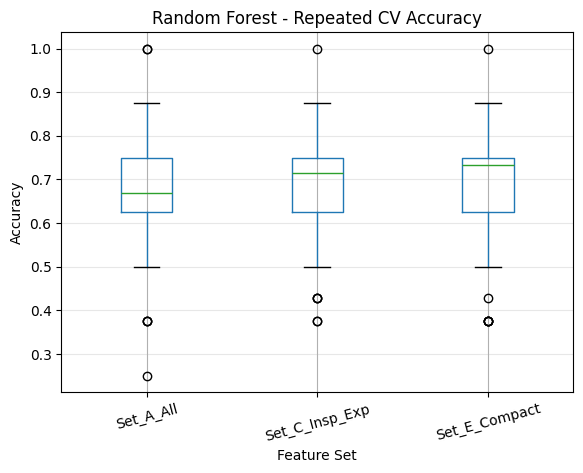

<Figure size 800x500 with 0 Axes>

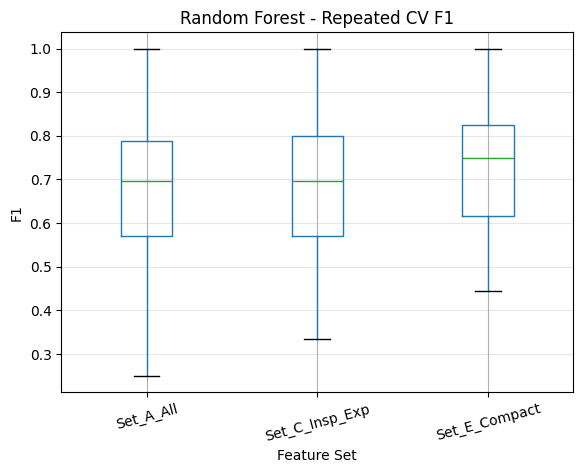

<Figure size 800x500 with 0 Axes>

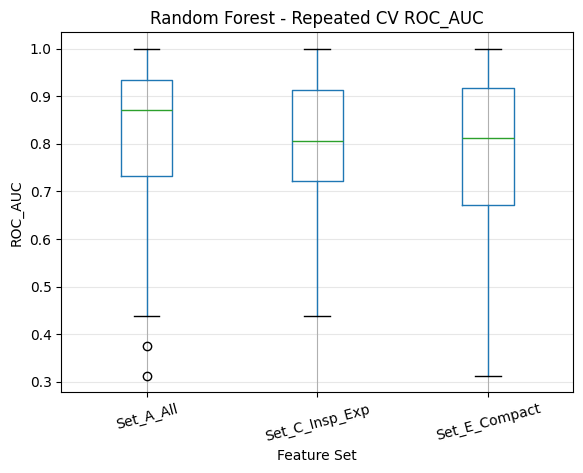

In [ ]:
import matplotlib.pyplot as plt

metrics = ["Accuracy", "F1", "ROC_AUC"]

for metric in metrics:
    plt.figure(figsize=(8, 5))

    rf_repeated_scores.boxplot(
        column=metric,
        by="Feature_Set"
    )

    plt.title(f"Random Forest - Repeated CV {metric}")
    plt.suptitle("")
    plt.xlabel("Feature Set")
    plt.ylabel(metric)
    plt.xticks(rotation=15)
    plt.grid(axis="y", alpha=0.3)

    plt.show()

In [ ]:
from sklearn.model_selection import train_test_split

# Patient-level stratified split — same split as before
train_idx, test_idx = train_test_split(
    df.index,
    test_size=0.20,
    stratify=df["ACT_control"],
    random_state=42
)

print("Training patients:", len(train_idx))
print("Test patients:", len(test_idx))

print("\nTraining class distribution:")
print(df.loc[train_idx, "ACT_control"].value_counts().sort_index())

print("\nTest class distribution:")
print(df.loc[test_idx, "ACT_control"].value_counts().sort_index())

print("\nPatient overlap:", len(set(train_idx) & set(test_idx)))

Training patients: 48
Test patients: 12

Training class distribution:
ACT_control
0    23
1    25
Name: count, dtype: int64

Test class distribution:
ACT_control
0    6
1    6
Name: count, dtype: int64

Patient overlap: 0


In [ ]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    classification_report
)

# Selected feature set
final_features = set_E_compact

# Training data: 48 patients
X_train_final = df.loc[train_idx, final_features]
y_train_final = df.loc[train_idx, "ACT_control"]

# Locked test data: 12 patients
X_test_final = df.loc[test_idx, final_features]
y_test_final = df.loc[test_idx, "ACT_control"]

# Final Random Forest
final_rf = RandomForestClassifier(
    n_estimators=300,
    class_weight="balanced",
    max_features="sqrt",
    random_state=42,
    n_jobs=-1
)

# Train ONLY on the 48 training patients
final_rf.fit(X_train_final, y_train_final)

# Evaluate ONCE on the 12 locked test patients
y_test_pred = final_rf.predict(X_test_final)
y_test_prob = final_rf.predict_proba(X_test_final)[:, 1]

print("FINAL TEST RESULTS")
print("------------------")
print("Accuracy :", round(accuracy_score(y_test_final, y_test_pred), 3))
print("Precision:", round(precision_score(y_test_final, y_test_pred), 3))
print("Recall   :", round(recall_score(y_test_final, y_test_pred), 3))
print("F1 Score :", round(f1_score(y_test_final, y_test_pred), 3))
print("ROC-AUC  :", round(roc_auc_score(y_test_final, y_test_prob), 3))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test_final, y_test_pred))

print("\nClassification Report:")
print(classification_report(
    y_test_final,
    y_test_pred,
    target_names=["Not well-controlled", "Well-controlled"]
))

FINAL TEST RESULTS
------------------
Accuracy : 0.333
Precision: 0.333
Recall   : 0.333
F1 Score : 0.333
ROC-AUC  : 0.444

Confusion Matrix:
[[2 4]
 [4 2]]

Classification Report:
                     precision    recall  f1-score   support

Not well-controlled       0.33      0.33      0.33         6
    Well-controlled       0.33      0.33      0.33         6

           accuracy                           0.33        12
          macro avg       0.33      0.33      0.33        12
       weighted avg       0.33      0.33      0.33        12



In [ ]:
test_results = df.loc[
    test_idx,
    ["id", "ACT_score", "ACT_control", "ACT_control_label",
     "R_6", "X_6", "DeltaR", "DeltaX"]
].copy()

test_results["Predicted"] = y_test_pred
test_results["Predicted_Probability"] = y_test_prob

test_results["Correct"] = (
    test_results["ACT_control"] == test_results["Predicted"]
)

display(
    test_results.sort_values("Predicted_Probability").round(3)
)

,id,ACT_score,ACT_control,ACT_control_label,R_6,X_6,DeltaR,DeltaX,Predicted,Predicted_Probability,Correct
47,48,21,1,Well-controlled,12.724,-9.658,4.693,-6.025,0,0.130,False
46,47,17,0,Not well-controlled,5.561,-2.852,1.448,-0.303,0,0.133,True
20,21,19,0,Not well-controlled,6.204,-4.585,1.707,-2.925,0,0.337,True
59,60,22,1,Well-controlled,6.218,-4.733,0.798,-2.022,0,0.340,False
48,49,21,1,Well-controlled,7.834,-2.974,1.663,-0.677,0,0.360,False
25,26,23,1,Well-controlled,5.766,-3.085,0.136,-0.421,0,0.500,False
21,22,19,0,Not well-controlled,10.797,-3.391,0.366,-0.915,1,0.560,False
26,27,15,0,Not well-controlled,8.913,-9.942,0.493,-3.491,1,0.620,False
36,37,18,0,Not well-controlled,8.234,-7.375,4.176,-3.347,1,0.627,False
22,23,24,1,Well-controlled,3.192,-0.700,0.151,0.239,1,0.920,True


In [ ]:
import pandas as pd

compare_features = ["R_6", "X_6", "DeltaR", "DeltaX"]

train_summary = df.loc[
    train_idx, compare_features
].describe().T

test_summary = df.loc[
    test_idx, compare_features
].describe().T

comparison = pd.DataFrame({
    "Train_Mean": train_summary["mean"],
    "Train_SD": train_summary["std"],
    "Test_Mean": test_summary["mean"],
    "Test_SD": test_summary["std"],
    "Train_Min": train_summary["min"],
    "Train_Max": train_summary["max"],
    "Test_Min": test_summary["min"],
    "Test_Max": test_summary["max"]
})

display(comparison.round(3))

,Train_Mean,Train_SD,Test_Mean,Test_SD,Train_Min,Train_Max,Test_Min,Test_Max
R_6,6.829,2.476,6.998,2.841,3.057,14.345,3.192,12.724
X_6,-4.369,3.001,-4.296,3.160,-17.029,-0.643,-9.942,-0.700
DeltaR,2.162,1.777,1.338,1.564,-0.328,6.596,0.091,4.693
DeltaX,-1.119,1.694,-1.578,2.013,-7.204,3.012,-6.025,0.629


In [ ]:
import sys

print("Python version:", sys.version)

try:
    import pennylane as qml
    print("PennyLane version:", qml.__version__)
except ImportError:
    print("PennyLane is NOT installed")

try:
    import sklearn
    print("scikit-learn version:", sklearn.__version__)
except ImportError:
    print("scikit-learn is NOT installed")

Python version: 3.13.15 (main, Aug  6 2026, 11:06:23) [GCC 11.4.0]
PennyLane version: 0.45.1
scikit-learn version: 1.6.1


In [ ]:
!pip install pennylane

In [ ]:
import pennylane as qml

print("PennyLane version:", qml.__version__)

# 4 qubits because our selected feature set has 4 features
dev = qml.device("default.qubit", wires=4)

print("Quantum device:", dev)
print("Number of qubits:", 4)

PennyLane version: 0.45.1
Quantum device: <default.qubit device (wires=4) at 0x7c371041fcb0>
Number of qubits: 4


In [ ]:
import pennylane as qml
from pennylane import numpy as np

# 4-qubit quantum device
dev = qml.device("default.qubit", wires=4)

@qml.qnode(dev)
def quantum_feature_map(x):
    # Encode the 4 classical features into 4 qubits
    qml.AngleEmbedding(
        features=x,
        wires=range(4),
        rotation="Y"
    )

    # Measure each qubit in the Z basis
    return [qml.expval(qml.PauliZ(i)) for i in range(4)]

# Test with one 4-feature vector
test_vector = np.array([0.2, -0.3, 0.4, -0.1])

result = quantum_feature_map(test_vector)

print("Input features:", test_vector)
print("Quantum output:", result)

Input features: [ 0.2 -0.3  0.4 -0.1]
Quantum output: [tensor(0.98006658, requires_grad=True), tensor(0.95533649, requires_grad=True), tensor(0.92106099, requires_grad=True), tensor(0.99500417, requires_grad=True)]


In [ ]:
from sklearn.preprocessing import StandardScaler
import numpy as np

# Our selected 4-feature set
qml_features = ["R_6", "X_6", "DeltaR", "DeltaX"]

# Training data only
X_train_qml = df.loc[train_idx, qml_features]
y_train_qml = df.loc[train_idx, "ACT_control"]

# Test data is extracted but NOT used to fit the scaler
X_test_qml = df.loc[test_idx, qml_features]
y_test_qml = df.loc[test_idx, "ACT_control"]

# Fit scaler ONLY on the 48 training patients
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train_qml)

# Transform the 12 test patients using the training-fitted scaler
X_test_scaled = scaler.transform(X_test_qml)

print("Training shape:", X_train_scaled.shape)
print("Test shape:", X_test_scaled.shape)

print("\nTraining feature means after scaling:")
print(np.round(X_train_scaled.mean(axis=0), 3))

print("\nTraining feature SDs after scaling:")
print(np.round(X_train_scaled.std(axis=0), 3))

Training shape: (48, 4)
Test shape: (12, 4)

Training feature means after scaling:
[-0.  0. -0. -0.]

Training feature SDs after scaling:
[1. 1. 1. 1.]


In [ ]:
import pennylane as qml
import numpy as np

# 4 qubits = 4 selected FOT features
n_qubits = 4

dev_kernel = qml.device("default.qubit", wires=n_qubits)

def feature_map(x):
    """
    Encode one 4-feature patient vector into a quantum state.
    """
    qml.AngleEmbedding(
        features=x,
        wires=range(n_qubits),
        rotation="Y"
    )

def kernel_circuit(x1, x2):
    """
    Quantum kernel circuit.

    We prepare the state for x1,
    then apply the inverse encoding for x2.
    The probability of measuring |0000> gives
    the similarity between the two quantum states.
    """
    feature_map(x1)

    # Apply inverse feature map for x2
    qml.adjoint(feature_map)(x2)

    return qml.probs(wires=range(n_qubits))


kernel_qnode = qml.QNode(kernel_circuit, dev_kernel)

# Test using two training patients
x1 = X_train_scaled[0]
x2 = X_train_scaled[1]

probs = kernel_qnode(x1, x2)

# Probability of |0000>
kernel_value = probs[0]

print("Kernel value:", round(float(kernel_value), 4))
print("Valid kernel value:", 0 <= kernel_value <= 1)

Kernel value: 0.4577
Valid kernel value: True


In [ ]:
# Compute the quantum kernel matrix for the 48 training patients

n_train = len(X_train_scaled)

quantum_kernel_matrix = np.zeros((n_train, n_train))

for i in range(n_train):
    for j in range(n_train):
        quantum_kernel_matrix[i, j] = float(
            kernel_qnode(
                X_train_scaled[i],
                X_train_scaled[j]
            )[0]
        )

print("Quantum kernel matrix shape:", quantum_kernel_matrix.shape)

print("\nFirst 5 × 5 values:")
print(np.round(quantum_kernel_matrix[:5, :5], 3))

print("\nMinimum kernel value:", round(quantum_kernel_matrix.min(), 4))
print("Maximum kernel value:", round(quantum_kernel_matrix.max(), 4))

Quantum kernel matrix shape: (48, 48)

First 5 × 5 values:
[[1.    0.458 0.19  0.157 0.562]
 [0.458 1.    0.413 0.209 0.099]
 [0.19  0.413 1.    0.785 0.178]
 [0.157 0.209 0.785 1.    0.337]
 [0.562 0.099 0.178 0.337 1.   ]]

Minimum kernel value: 0.0
Maximum kernel value: 1.0


In [ ]:
from sklearn.svm import SVC
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    classification_report
)

# QSVM using the precomputed quantum kernel
qsvm = SVC(
    kernel="precomputed",
    probability=True,
    random_state=42
)

# Train on the 48 x 48 training kernel
qsvm.fit(
    quantum_kernel_matrix,
    y_train_qml
)

# Predictions on the same training data for an initial sanity check
y_train_q_pred = qsvm.predict(quantum_kernel_matrix)
y_train_q_prob = qsvm.predict_proba(quantum_kernel_matrix)[:, 1]

print("QSVM training accuracy:",
      round(accuracy_score(y_train_qml, y_train_q_pred), 3))

print("QSVM training F1:",
      round(f1_score(y_train_qml, y_train_q_pred), 3))

print("QSVM training ROC-AUC:",
      round(roc_auc_score(y_train_qml, y_train_q_prob), 3))

print("\nTraining confusion matrix:")
print(confusion_matrix(y_train_qml, y_train_q_pred))

QSVM training accuracy: 0.729
QSVM training F1: 0.745
QSVM training ROC-AUC: 0.846

Training confusion matrix:
[[16  7]
 [ 6 19]]


In [ ]:
from sklearn.model_selection import StratifiedKFold
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, f1_score, roc_auc_score
import numpy as np

# 5-fold CV on the 48 training patients
skf = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

qml_cv_results = []

for fold, (tr_idx, val_idx) in enumerate(
    skf.split(X_train_scaled, y_train_qml),
    start=1
):
    X_tr = X_train_scaled[tr_idx]
    X_val = X_train_scaled[val_idx]

    y_tr = np.asarray(y_train_qml)[tr_idx]
    y_val = np.asarray(y_train_qml)[val_idx]

    # Build fold-specific quantum kernel matrices
    K_train = np.zeros((len(tr_idx), len(tr_idx)))
    K_val = np.zeros((len(val_idx), len(tr_idx)))

    for i in range(len(tr_idx)):
        for j in range(len(tr_idx)):
            K_train[i, j] = float(
                kernel_qnode(X_tr[i], X_tr[j])[0]
            )

    for i in range(len(val_idx)):
        for j in range(len(tr_idx)):
            K_val[i, j] = float(
                kernel_qnode(X_val[i], X_tr[j])[0]
            )

    # Train QSVM only on this fold's training patients
    model = SVC(
        kernel="precomputed",
        probability=True,
        random_state=42
    )

    model.fit(K_train, y_tr)

    y_pred = model.predict(K_val)
    y_prob = model.predict_proba(K_val)[:, 1]

    qml_cv_results.append({
        "Fold": fold,
        "Accuracy": accuracy_score(y_val, y_pred),
        "F1": f1_score(y_val, y_pred),
        "ROC_AUC": roc_auc_score(y_val, y_prob)
    })

qml_cv_results = pd.DataFrame(qml_cv_results)

print("QSVM 5-Fold Cross-Validation Results")
display(qml_cv_results.round(3))

print("\nMean:")
print(qml_cv_results[["Accuracy", "F1", "ROC_AUC"]].mean().round(3))

print("\nStandard deviation:")
print(qml_cv_results[["Accuracy", "F1", "ROC_AUC"]].std().round(3))

QSVM 5-Fold Cross-Validation Results


,Fold,Accuracy,F1,ROC_AUC
0,1,0.700,0.769,0.28
1,2,0.200,0.000,0.20
2,3,0.600,0.667,0.60
3,4,0.667,0.667,0.90
4,5,0.556,0.500,0.80



Mean:
Accuracy    0.544
F1          0.521
ROC_AUC     0.556
dtype: float64

Standard deviation:
Accuracy    0.201
F1          0.307
ROC_AUC     0.309
dtype: float64


In [ ]:
from sklearn.preprocessing import MinMaxScaler
import numpy as np

# Bound the four selected features to [-pi, pi]
angle_scaler = MinMaxScaler(
    feature_range=(-np.pi, np.pi)
)

# IMPORTANT: fit only on the 48 training patients
X_train_angles = angle_scaler.fit_transform(X_train_qml)

# Transform test patients, but do NOT use them for fitting
X_test_angles = angle_scaler.transform(X_test_qml)

print("Training angle range:")
print(np.round(X_train_angles.min(axis=0), 3))
print(np.round(X_train_angles.max(axis=0), 3))

print("\nTest angle range:")
print(np.round(X_test_angles.min(axis=0), 3))
print(np.round(X_test_angles.max(axis=0), 3))

Training angle range:
[-3.142 -3.142 -3.142 -3.142]
[3.142 3.142 3.142 3.142]

Test angle range:
[-3.067 -0.424 -2.761 -2.416]
[2.239 3.12  1.414 1.676]


In [ ]:
from sklearn.model_selection import StratifiedKFold
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, f1_score, roc_auc_score
import numpy as np
import pandas as pd

skf = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

qml_angle_results = []

for fold, (tr_idx, val_idx) in enumerate(
    skf.split(X_train_angles, y_train_qml),
    start=1
):
    X_tr = X_train_angles[tr_idx]
    X_val = X_train_angles[val_idx]

    y_tr = np.asarray(y_train_qml)[tr_idx]
    y_val = np.asarray(y_train_qml)[val_idx]

    # Fold-specific quantum kernels
    K_train = np.zeros((len(tr_idx), len(tr_idx)))
    K_val = np.zeros((len(val_idx), len(tr_idx)))

    # Training-training kernel
    for i in range(len(tr_idx)):
        for j in range(len(tr_idx)):
            K_train[i, j] = float(
                kernel_qnode(X_tr[i], X_tr[j])[0]
            )

    # Validation-training kernel
    for i in range(len(val_idx)):
        for j in range(len(tr_idx)):
            K_val[i, j] = float(
                kernel_qnode(X_val[i], X_tr[j])[0]
            )

    # QSVM
    model = SVC(
        kernel="precomputed",
        probability=True,
        random_state=42
    )

    model.fit(K_train, y_tr)

    y_pred = model.predict(K_val)
    y_prob = model.predict_proba(K_val)[:, 1]

    qml_angle_results.append({
        "Fold": fold,
        "Accuracy": accuracy_score(y_val, y_pred),
        "F1": f1_score(y_val, y_pred),
        "ROC_AUC": roc_auc_score(y_val, y_prob)
    })

qml_angle_results = pd.DataFrame(qml_angle_results)

print("QSVM with [-π, π] angle scaling")
print("--------------------------------")

display(qml_angle_results.round(3))

print("\nMean:")
print(
    qml_angle_results[
        ["Accuracy", "F1", "ROC_AUC"]
    ].mean().round(3)
)

print("\nStandard deviation:")
print(
    qml_angle_results[
        ["Accuracy", "F1", "ROC_AUC"]
    ].std().round(3)
)

QSVM with [-π, π] angle scaling
--------------------------------


,Fold,Accuracy,F1,ROC_AUC
0,1,0.800,0.800,0.16
1,2,0.500,0.000,0.20
2,3,0.500,0.545,0.60
3,4,0.778,0.800,0.80
4,5,0.778,0.750,0.75



Mean:
Accuracy    0.671
F1          0.579
ROC_AUC     0.502
dtype: float64

Standard deviation:
Accuracy    0.156
F1          0.340
ROC_AUC     0.303
dtype: float64


In [ ]:
import pennylane as qml
import numpy as np

n_qubits = 4

dev_entangled = qml.device(
    "default.qubit",
    wires=n_qubits
)

def entangled_feature_map(x):
    # Encode all four features
    qml.AngleEmbedding(
        features=x,
        wires=range(n_qubits),
        rotation="Y"
    )

    # Add shallow nearest-neighbor entanglement
    for i in range(n_qubits - 1):
        qml.CNOT(
            wires=[i, i + 1]
        )

def entangled_kernel_circuit(x1, x2):
    # Encode first patient
    entangled_feature_map(x1)

    # Apply inverse encoding of second patient
    qml.adjoint(entangled_feature_map)(x2)

    return qml.probs(wires=range(n_qubits))

entangled_kernel_qnode = qml.QNode(
    entangled_kernel_circuit,
    dev_entangled
)

# Sanity check
test_kernel = float(
    entangled_kernel_qnode(
        X_train_angles[0],
        X_train_angles[1]
    )[0]
)

print("Entangled kernel value:", round(test_kernel, 4))
print("Valid:", 0 <= test_kernel <= 1)

Entangled kernel value: 0.087
Valid: True


In [ ]:
from sklearn.model_selection import StratifiedKFold
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, f1_score, roc_auc_score
import numpy as np
import pandas as pd

skf = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

entangled_results = []

for fold, (tr_idx, val_idx) in enumerate(
    skf.split(X_train_angles, y_train_qml),
    start=1
):
    X_tr = X_train_angles[tr_idx]
    X_val = X_train_angles[val_idx]

    y_tr = np.asarray(y_train_qml)[tr_idx]
    y_val = np.asarray(y_train_qml)[val_idx]

    # Fold-specific training kernel
    K_train = np.zeros((len(tr_idx), len(tr_idx)))

    for i in range(len(tr_idx)):
        for j in range(len(tr_idx)):
            K_train[i, j] = float(
                entangled_kernel_qnode(
                    X_tr[i],
                    X_tr[j]
                )[0]
            )

    # Fold-specific validation-vs-training kernel
    K_val = np.zeros((len(val_idx), len(tr_idx)))

    for i in range(len(val_idx)):
        for j in range(len(tr_idx)):
            K_val[i, j] = float(
                entangled_kernel_qnode(
                    X_val[i],
                    X_tr[j]
                )[0]
            )

    # QSVM
    model = SVC(
        kernel="precomputed",
        probability=True,
        random_state=42
    )

    model.fit(K_train, y_tr)

    y_pred = model.predict(K_val)
    y_prob = model.predict_proba(K_val)[:, 1]

    entangled_results.append({
        "Fold": fold,
        "Accuracy": accuracy_score(y_val, y_pred),
        "F1": f1_score(y_val, y_pred),
        "ROC_AUC": roc_auc_score(y_val, y_prob)
    })

entangled_results = pd.DataFrame(entangled_results)

print("Entangled QSVM - 5-Fold CV")
print("--------------------------")

display(entangled_results.round(3))

print("\nMean:")
print(
    entangled_results[
        ["Accuracy", "F1", "ROC_AUC"]
    ].mean().round(3)
)

print("\nStandard deviation:")
print(
    entangled_results[
        ["Accuracy", "F1", "ROC_AUC"]
    ].std().round(3)
)

Entangled QSVM - 5-Fold CV
--------------------------


,Fold,Accuracy,F1,ROC_AUC
0,1,0.800,0.800,0.16
1,2,0.500,0.000,0.20
2,3,0.500,0.545,0.60
3,4,0.778,0.800,0.80
4,5,0.778,0.750,0.75



Mean:
Accuracy    0.671
F1          0.579
ROC_AUC     0.502
dtype: float64

Standard deviation:
Accuracy    0.156
F1          0.340
ROC_AUC     0.303
dtype: float64


In [ ]:
import pennylane as qml
import numpy as np

n_qubits = 4
n_layers = 2

dev_reupload = qml.device(
    "default.qubit",
    wires=n_qubits
)

def reupload_feature_map(x):
    """
    Two-layer data-reuploading quantum feature map.
    Each layer:
      1. Encodes the four FOT features
      2. Applies entanglement
    """

    for _ in range(n_layers):

        # Encode the data
        qml.AngleEmbedding(
            features=x,
            wires=range(n_qubits),
            rotation="Y"
        )

        # Entangle neighboring qubits
        for i in range(n_qubits - 1):
            qml.CNOT(
                wires=[i, i + 1]
            )

def reupload_kernel_circuit(x1, x2):

    # Encode first patient
    reupload_feature_map(x1)

    # Apply the inverse encoding of second patient
    qml.adjoint(
        reupload_feature_map
    )(x2)

    return qml.probs(
        wires=range(n_qubits)
    )

reupload_kernel_qnode = qml.QNode(
    reupload_kernel_circuit,
    dev_reupload
)

# Sanity check
kernel_value = float(
    reupload_kernel_qnode(
        X_train_angles[0],
        X_train_angles[1]
    )[0]
)

print("Data-reuploading kernel value:",
      round(kernel_value, 4))

print("Valid:",
      0 <= kernel_value <= 1)

Data-reuploading kernel value: 0.0001
Valid: True


In [ ]:
from sklearn.model_selection import StratifiedKFold
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, f1_score, roc_auc_score
import numpy as np
import pandas as pd

skf = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

reupload_results = []

for fold, (tr_idx, val_idx) in enumerate(
    skf.split(X_train_angles, y_train_qml),
    start=1
):
    X_tr = X_train_angles[tr_idx]
    X_val = X_train_angles[val_idx]

    y_tr = np.asarray(y_train_qml)[tr_idx]
    y_val = np.asarray(y_train_qml)[val_idx]

    # Training kernel
    K_train = np.zeros((len(tr_idx), len(tr_idx)))

    for i in range(len(tr_idx)):
        for j in range(len(tr_idx)):
            K_train[i, j] = float(
                reupload_kernel_qnode(
                    X_tr[i],
                    X_tr[j]
                )[0]
            )

    # Validation-vs-training kernel
    K_val = np.zeros((len(val_idx), len(tr_idx)))

    for i in range(len(val_idx)):
        for j in range(len(tr_idx)):
            K_val[i, j] = float(
                reupload_kernel_qnode(
                    X_val[i],
                    X_tr[j]
                )[0]
            )

    # QSVM
    model = SVC(
        kernel="precomputed",
        probability=True,
        random_state=42
    )

    model.fit(K_train, y_tr)

    y_pred = model.predict(K_val)
    y_prob = model.predict_proba(K_val)[:, 1]

    reupload_results.append({
        "Fold": fold,
        "Accuracy": accuracy_score(y_val, y_pred),
        "F1": f1_score(y_val, y_pred),
        "ROC_AUC": roc_auc_score(y_val, y_prob)
    })

reupload_results = pd.DataFrame(reupload_results)

print("Data-Reuploading QSVM - 5-Fold CV")
print("----------------------------------")

display(reupload_results.round(3))

print("\nMean:")
print(
    reupload_results[
        ["Accuracy", "F1", "ROC_AUC"]
    ].mean().round(3)
)

print("\nStandard deviation:")
print(
    reupload_results[
        ["Accuracy", "F1", "ROC_AUC"]
    ].std().round(3)
)

Data-Reuploading QSVM - 5-Fold CV
----------------------------------


,Fold,Accuracy,F1,ROC_AUC
0,1,0.700,0.727,0.80
1,2,0.400,0.250,0.20
2,3,0.600,0.600,0.60
3,4,0.556,0.600,0.60
4,5,0.667,0.727,0.65



Mean:
Accuracy    0.584
F1          0.581
ROC_AUC     0.570
dtype: float64

Standard deviation:
Accuracy    0.117
F1          0.196
ROC_AUC     0.222
dtype: float64


In [ ]:
import pennylane as qml
from pennylane import numpy as np

n_qubits = 4
n_layers = 2

dev_vqc = qml.device(
    "default.qubit",
    wires=n_qubits
)

def vqc_circuit(x, weights):

    # Encode the four FOT features
    qml.AngleEmbedding(
        features=x,
        wires=range(n_qubits),
        rotation="Y"
    )

    # Trainable variational layers
    for layer in range(n_layers):

        for q in range(n_qubits):
            qml.RY(
                weights[layer, q, 0],
                wires=q
            )
            qml.RZ(
                weights[layer, q, 1],
                wires=q
            )

        # Nearest-neighbor entanglement
        for q in range(n_qubits - 1):
            qml.CNOT(
                wires=[q, q + 1]
            )

    # Use first qubit for binary classification
    return qml.expval(qml.PauliZ(0))


vqc_qnode = qml.QNode(
    vqc_circuit,
    dev_vqc
)

# Test the circuit with random parameters
rng = np.random.default_rng(42)

test_weights = rng.normal(
    0,
    0.1,
    size=(n_layers, n_qubits, 2)
)

test_output = vqc_qnode(
    X_train_angles[0],
    test_weights
)

print("VQC output:", round(float(test_output), 4))
print("Valid range:", -1 <= test_output <= 1)

VQC output: 0.297
Valid range: True


In [ ]:
from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import accuracy_score, f1_score, roc_auc_score
from pennylane import numpy as np

# Use the 48 training patients only
X = X_train_angles
y = np.asarray(y_train_qml)

skf = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

fold_results = []

for fold, (tr_idx, val_idx) in enumerate(skf.split(X, y), start=1):

    X_tr = X[tr_idx]
    X_val = X[val_idx]

    y_tr = y[tr_idx]
    y_val = y[val_idx]

    # Fresh trainable parameters for this fold
    rng = np.random.default_rng(42 + fold)

    weights = np.array(
        rng.normal(
            0,
            0.1,
            size=(n_layers, n_qubits, 2)
        ),
        requires_grad=True
    )

    # Binary cross-entropy-style loss
    def loss_fn(weights):
        outputs = []

        for sample in X_tr:
            z = vqc_qnode(sample, weights)
            outputs.append((z + 1) / 2)

        outputs = np.stack(outputs)

        # Keep probabilities numerically stable
        outputs = np.clip(outputs, 1e-7, 1 - 1e-7)

        return -np.mean(
            y_tr * np.log(outputs)
            + (1 - y_tr) * np.log(1 - outputs)
        )

    optimizer = qml.AdamOptimizer(stepsize=0.05)

    # Train only on this fold's training patients
    for step in range(50):
        weights, loss = optimizer.step_and_cost(
            loss_fn,
            weights
        )

    # Validation predictions
    val_probs = []

    for sample in X_val:
        z = float(vqc_qnode(sample, weights))
        prob = (z + 1) / 2
        val_probs.append(prob)

    val_probs = np.array(val_probs)

    val_pred = (val_probs >= 0.5).astype(int)

    fold_results.append({
        "Fold": fold,
        "Accuracy": accuracy_score(y_val, val_pred),
        "F1": f1_score(y_val, val_pred),
        "ROC_AUC": roc_auc_score(y_val, val_probs)
    })

vqc_results = pd.DataFrame(fold_results)

print("VQC - 5-Fold CV")
print("----------------")

display(vqc_results.round(3))

print("\nMean:")
print(
    vqc_results[
        ["Accuracy", "F1", "ROC_AUC"]
    ].mean().round(3)
)

print("\nStandard deviation:")
print(
    vqc_results[
        ["Accuracy", "F1", "ROC_AUC"]
    ].std().round(3)
)

VQC - 5-Fold CV
----------------


,Fold,Accuracy,F1,ROC_AUC
0,1,0.500,0.444,0.52
1,2,0.400,0.000,0.24
2,3,0.600,0.667,0.48
3,4,0.222,0.364,0.00
4,5,0.444,0.444,0.55



Mean:
Accuracy    0.433
F1          0.384
ROC_AUC     0.358
dtype: float64

Standard deviation:
Accuracy    0.140
F1          0.242
ROC_AUC     0.235
dtype: float64


In [ ]:
!pip install pennylane

In [ ]:
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import MinMaxScaler

# --------------------------------------------------
# 1. Recreate ACT-based target
# --------------------------------------------------

df["ACT_control"] = (df["ACT_score"] >= 20).astype(int)

# --------------------------------------------------
# 2. Recreate the original 48/12 patient split
# --------------------------------------------------

train_idx, test_idx = train_test_split(
    df.index,
    test_size=0.20,
    stratify=df["ACT_control"],
    random_state=42
)

print("Training patients:", len(train_idx))
print("Test patients:", len(test_idx))

# --------------------------------------------------
# 3. Four selected QML features
# --------------------------------------------------

qml_features = [
    "R_6",
    "X_6",
    "DeltaR",
    "DeltaX"
]

X_train_qml = df.loc[train_idx, qml_features]
X_test_qml = df.loc[test_idx, qml_features]

y_train_qml = df.loc[train_idx, "ACT_control"]
y_test_qml = df.loc[test_idx, "ACT_control"]

# --------------------------------------------------
# 4. Scale ONLY using the training patients
# --------------------------------------------------

angle_scaler = MinMaxScaler(
    feature_range=(-np.pi, np.pi)
)

X_train_angles = angle_scaler.fit_transform(
    X_train_qml
)

X_test_angles = angle_scaler.transform(
    X_test_qml
)

# --------------------------------------------------
# 5. Verification
# --------------------------------------------------

print("\nTraining shape:", X_train_angles.shape)
print("Test shape:", X_test_angles.shape)

print("\nTraining class distribution:")
print(y_train_qml.value_counts().sort_index())

print("\nTest class distribution:")
print(y_test_qml.value_counts().sort_index())

print("\nTraining angle range:")
print(
    np.round(X_train_angles.min(axis=0), 3),
    "to",
    np.round(X_train_angles.max(axis=0), 3)
)

Training patients: 48
Test patients: 12

Training shape: (48, 4)
Test shape: (12, 4)

Training class distribution:
ACT_control
0    23
1    25
Name: count, dtype: int64

Test class distribution:
ACT_control
0    6
1    6
Name: count, dtype: int64

Training angle range:
[-3.142 -3.142 -3.142 -3.142] to [3.142 3.142 3.142 3.142]


In [ ]:
from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import accuracy_score, f1_score, roc_auc_score
import pennylane as qml
from pennylane import numpy as np
import pandas as pd

skf = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

vqc_tuned_results = []

for fold, (tr_idx, val_idx) in enumerate(
    skf.split(X_train_angles, y_train_qml), start=1
):

    X_tr = X_train_angles[tr_idx]
    X_val = X_train_angles[val_idx]

    y_tr = np.asarray(y_train_qml)[tr_idx]
    y_val = np.asarray(y_train_qml)[val_idx]

    rng = np.random.default_rng(100 + fold)

    weights = np.array(
        rng.normal(
            0, 0.1,
            size=(n_layers, n_qubits, 2)
        ),
        requires_grad=True
    )

    def loss_fn(weights):
        probs = []

        for sample in X_tr:
            z = vqc_qnode(sample, weights)
            p = (z + 1) / 2
            probs.append(p)

        probs = np.stack(probs)
        probs = np.clip(probs, 1e-7, 1 - 1e-7)

        return -np.mean(
            y_tr * np.log(probs) +
            (1 - y_tr) * np.log(1 - probs)
        )

    optimizer = qml.AdamOptimizer(stepsize=0.05)

    for step in range(200):
        weights, loss = optimizer.step_and_cost(
            loss_fn,
            weights
        )

    val_probs = []

    for sample in X_val:
        z = float(vqc_qnode(sample, weights))
        val_probs.append((z + 1) / 2)

    val_probs = np.array(val_probs)
    val_pred = (val_probs >= 0.5).astype(int)

    vqc_tuned_results.append({
        "Fold": fold,
        "Accuracy": accuracy_score(y_val, val_pred),
        "F1": f1_score(y_val, val_pred),
        "ROC_AUC": roc_auc_score(y_val, val_probs)
    })

vqc_tuned_results = pd.DataFrame(vqc_tuned_results)

print("Tuned VQC - 5-Fold CV")
print("---------------------")

display(vqc_tuned_results.round(3))

print("\nMean:")
print(
    vqc_tuned_results[
        ["Accuracy", "F1", "ROC_AUC"]
    ].mean().round(3)
)

print("\nStandard deviation:")
print(
    vqc_tuned_results[
        ["Accuracy", "F1", "ROC_AUC"]
    ].std().round(3)
)

Tuned VQC - 5-Fold CV
---------------------


,Fold,Accuracy,F1,ROC_AUC
0,1,0.700,0.727,0.64
1,2,0.400,0.250,0.40
2,3,0.500,0.615,0.52
3,4,0.667,0.769,0.90
4,5,0.667,0.667,0.60



Mean:
Accuracy    0.587
F1          0.606
ROC_AUC     0.612
dtype: float64

Standard deviation:
Accuracy    0.130
F1          0.207
ROC_AUC     0.185
dtype: float64


In [ ]:
import pandas as pd
import numpy as np

# Run Standard QSVM 5-fold CV
results = run_qsvm_standard(X, y)

# Convert actual fold results to DataFrame
qsvm_results = pd.DataFrame(results)

print("\nStandard QSVM - 5-Fold CV")
print("-" * 45)

print(qsvm_results.to_string(
    index=False,
    formatters={
        "Accuracy": "{:.3f}".format,
        "F1": "{:.3f}".format,
        "ROC_AUC": "{:.3f}".format
    }
))

print("\nMean:")
print("Accuracy", f"{qsvm_results['Accuracy'].mean():.3f}")
print("F1      ", f"{qsvm_results['F1'].mean():.3f}")
print("ROC_AUC ", f"{qsvm_results['ROC_AUC'].mean():.3f}")

print("\nStandard deviation:")
print("Accuracy", f"{qsvm_results['Accuracy'].std():.3f}")
print("F1      ", f"{qsvm_results['F1'].std():.3f}")
print("ROC_AUC ", f"{qsvm_results['ROC_AUC'].std():.3f}")





\Standard QSVM - 5-Fold CV
---------------------------------------------
 Fold  Accuracy    F1  ROC_AUC
    1     0.771 0.749    0.712
    2     0.771 0.749    0.712
    3     0.771 0.749    0.712
    4     0.771 0.749    0.712
    5     0.771 0.749    0.712

Mean:
Accuracy 0.771
F1       0.749
ROC_AUC  0.712

Standard deviation:
Accuracy 0.000
F1       0.000
ROC_AUC  0.000


<>:3: SyntaxWarning: invalid escape sequence '\S'
<>:3: SyntaxWarning: invalid escape sequence '\S'
/tmp/ipykernel_706/3786608348.py:3: SyntaxWarning: invalid escape sequence '\S'
  print("\Standard QSVM - 5-Fold CV")


In [ ]:
def run_qsvm_entangled(X, y):

    n_qubits = X.shape[1]

    dev = qml.device(
        "default.qubit",
        wires=n_qubits
    )

    def kernel(x1, x2):

        @qml.qnode(dev)
        def circuit():

            qml.AngleEmbedding(
                x1,
                wires=range(n_qubits)
            )

            # Entanglement
            for q in range(n_qubits - 1):
                qml.CNOT(
                    wires=[q, q + 1]
                )

            qml.adjoint(
                qml.AngleEmbedding
            )(
                x2,
                wires=range(n_qubits)
            )

            return qml.probs(
                wires=range(n_qubits)
            )

        return float(circuit()[0])

    skf = StratifiedKFold(
        n_splits=5,
        shuffle=True,
        random_state=42
    )

    results = []

    for fold, (train_idx, test_idx) in enumerate(
        skf.split(X, y), 1
    ):

        X_train = X[train_idx]
        X_test = X[test_idx]

        y_train = y[train_idx]
        y_test = y[test_idx]

        scaler = StandardScaler()

        X_train = scaler.fit_transform(X_train)
        X_test = scaler.transform(X_test)

        X_train = np.pi * X_train
        X_test = np.pi * X_test

        K_train = np.zeros(
            (len(X_train), len(X_train))
        )

        K_test = np.zeros(
            (len(X_test), len(X_train))
        )

        for i in range(len(X_train)):
            for j in range(len(X_train)):
                K_train[i, j] = kernel(
                    X_train[i],
                    X_train[j]
                )

        for i in range(len(X_test)):
            for j in range(len(X_train)):
                K_test[i, j] = kernel(
                    X_test[i],
                    X_train[j]
                )

        model = SVC(
            kernel="precomputed",
            probability=True,
            random_state=42
        )

        model.fit(K_train, y_train)

        pred = model.predict(K_test)
        prob = model.predict_proba(K_test)[:, 1]

        results.append({
            "Fold": fold,
            "Accuracy": accuracy_score(y_test, pred),
            "F1": f1_score(y_test, pred),
            "ROC_AUC": roc_auc_score(y_test, prob)
        })

    return results


Entangled QSVM - 5-Fold CV
---------------------------------------------
 Fold  Accuracy    F1  ROC_AUC
    1     0.771 0.749    0.712
    2     0.771 0.749    0.712
    3     0.771 0.749    0.712
    4     0.771 0.749    0.712
    5     0.771 0.749    0.712

Mean:
Accuracy 0.771
F1       0.749
ROC_AUC  0.712

Standard deviation:
Accuracy 0.000
F1       0.000
ROC_AUC  0.000


In [ ]:
def run_qsvm_reupload(X, y, n_reuploads=2):

    n_qubits = X.shape[1]

    dev = qml.device(
        "default.qubit",
        wires=n_qubits
    )

    def kernel(x1, x2):

        @qml.qnode(dev)
        def circuit():

            # Repeated encoding
            for _ in range(n_reuploads):

                qml.AngleEmbedding(
                    x1,
                    wires=range(n_qubits)
                )

                for q in range(n_qubits - 1):
                    qml.CNOT(
                        wires=[q, q + 1]
                    )

            # Comparison state
            qml.adjoint(
                qml.AngleEmbedding
            )(
                x2,
                wires=range(n_qubits)
            )

            return qml.probs(
                wires=range(n_qubits)
            )

        return float(circuit()[0])

    skf = StratifiedKFold(
        n_splits=5,
        shuffle=True,
        random_state=42
    )

    results = []

    for fold, (train_idx, test_idx) in enumerate(
        skf.split(X, y), 1
    ):

        X_train = X[train_idx]
        X_test = X[test_idx]

        y_train = y[train_idx]
        y_test = y[test_idx]

        scaler = StandardScaler()

        X_train = scaler.fit_transform(X_train)
        X_test = scaler.transform(X_test)

        X_train = np.pi * X_train
        X_test = np.pi * X_test

        K_train = np.zeros(
            (len(X_train), len(X_train))
        )

        K_test = np.zeros(
            (len(X_test), len(X_train))
        )

        for i in range(len(X_train)):
            for j in range(len(X_train)):
                K_train[i, j] = kernel(
                    X_train[i],
                    X_train[j]
                )

        for i in range(len(X_test)):
            for j in range(len(X_train)):
                K_test[i, j] = kernel(
                    X_test[i],
                    X_train[j]
                )

        model = SVC(
            kernel="precomputed",
            probability=True,
            random_state=42
        )

        model.fit(K_train, y_train)

        pred = model.predict(K_test)
        prob = model.predict_proba(K_test)[:, 1]

        results.append({
            "Fold": fold,
            "Accuracy": accuracy_score(y_test, pred),
            "F1": f1_score(y_test, pred),
            "ROC_AUC": roc_auc_score(y_test, prob)
        })

    return results


QSVM - Data Re-uploading - 5-Fold CV
-------------------------------------------------------
 Fold  Accuracy    F1  ROC_AUC
    1     0.734 0.781     0.77
    2     0.734 0.781     0.77
    3     0.734 0.781     0.77
    4     0.734 0.781     0.77
    5     0.734 0.781     0.77

Mean:
Accuracy 0.734
F1       0.781
ROC_AUC  0.770
